# RADIOBLOCKS scenarios A, B and C at 5 GHz: a compact Gaussian source observed with the EVN + AVN + SKA-Mid

This notebook tests a **self-calibration + closure-quantity imaging pipeline** on a simulated 5 GHz (C-band) VLBI observation with the **European VLBI Network (EVN) plus the African VLBI Network (AVN), including the SKA-Mid telescope** (the array is called **EVN + AVN + SKA-Mid** throughout), under the three RADIOBLOCKS error scenarios (the same definitions as in the `ehtim` hands-on and in the LBA + SKA-Low 250 MHz notebook of this project):

| Scenario | Errors | `observe()` settings |
|---|---|---|
| Reference (not a scenario) | none | `add_th_noise=False`, `ampcal=True`, `phasecal=True` |
| **A** | thermal noise only | `add_th_noise=True`, `ampcal=True`, `phasecal=True` |
| **B** | thermal noise + gain errors + generic (`ehtim` random) phase errors | `add_th_noise=True`, `ampcal=False` + `gain_offset`, `gainp`, `phasecal=False` |
| **C** | thermal noise + gain errors + structured atmospheric corruptions: ionospheric (dTEC) and tropospheric (delay) phase screens | same noise and gains as B, `phasecal=True`, plus the ionospheric and tropospheric screens of Section 6 |

**Configuration**
* **Array: EVN + AVN + SKA-Mid, 20 stations, SKA-Mid included in every simulation:** 11 EVN stations (Effelsberg, Irbene, Jodrell Bank, Medicina, Noto, Onsala, Sardinia, Tianma, Toruń, Westerbork, Yebes); **4 SKA-Mid elements** in South Africa (the SKA-Mid array phased up as a single VLBI station, `S5`, and three individual SKA-Mid dishes, `S004`, `S008`, `S133`); and 5 AVN stations (Hartebeesthoek, and stations in Ghana, Namibia, Botswana and Kenya). The **EVN alone (no SKA)** appears only in the uv-coverage comparison of Section 3.
* **Observing frequency / bandwidth:** 5 GHz / 256 MHz (modelled in 32 channels for the in-band decorrelation of scenario C).
* **Source:** circular Gaussian, 0.5 mas FWHM, 1 Jy, at RA 12 h, Dec +4° (a compact AGN core or VLBI calibrator). It is built in the notebook; no external file is needed.
* **Observing window:** the 6-h window (UTC) with the most visibilities for this source, selected automatically as in the LBA notebook (Section 3); 2-min scans every 10 min, 10° elevation limit (the scan setup of the 5 GHz hands-on).

> **Important:** the EVN SEFDs are typical published C-band values; the SEFDs of the AVN stations and of the **SKA-Mid** elements (which are not yet VLBI-capable) are **assumed** values for a future network (Section 1). The thermal-noise level, and therefore all the numbers below, depend on them.

**Structure:** 0. Setup · 1. Array and observing parameters · 2. Source model · 3. Reference observation and uv-coverage · 4–6. Scenarios A, B, C · 7. Self-calibration and closure check · 8. Imaging · **9. Metrics and diagnostics · 10. Comparison of imaging strategies · 11. Self-calibration to the final images (how well do the closures work?) · 12. Discussion of the results** · 13. Export (UVFITS, figures, images, tables) · 14. Conclusions and limitations · References.

## 0. Setup

`ehtim` 1.2.10 uses the old NumPy C API, so it needs **NumPy < 2**. If `ehtim` is not installed, the cell installs it; in Google Colab the install downgrades NumPy, so **restart the runtime once** (Runtime → Restart session) and run the notebook again from the top. All Fourier transforms use `ttype='fast'`, so the NFFT library is not needed (the `No NFFT installed` warning can be ignored).

In [1]:
import os, io, time, contextlib, itertools, warnings
import numpy as np
import matplotlib.pyplot as plt
try:
    import ehtim as eh
except ImportError:                       # e.g. a fresh Google Colab session
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ehtim==1.2.10', 'numpy>=1.19,<2.0'])
    import ehtim as eh                    # in Colab: restart the runtime if this import fails after the install
from ehtim.calibrating import self_cal as sc
warnings.filterwarnings('ignore', category=RuntimeWarning)     # harmless divide-by-zero warnings of ehtim's TV regularizer

# ---- Output folder: every figure, visibility file and image is collected here (see Section 12) ----
OUT_DIR = 'results_VLBI_5GHz_Gaussian'
for sub in ('figures', 'visibilities', 'images', 'tables'):
    os.makedirs(f'{OUT_DIR}/{sub}', exist_ok=True)

def save_fig(fig, name):
    fig.savefig(f'{OUT_DIR}/figures/{name}.png', dpi=150, bbox_inches='tight')

mas = eh.RADPERUAS*1e3          # 1 mas in radians
silent = lambda: contextlib.redirect_stdout(io.StringIO())     # hides ehtim's progress messages
T0 = time.time()

Welcome to eht-imaging! v 1.2.10 



## 1. Array, sensitivities (SEFD) and observing parameters

**Stations and SEFDs.** The array file format is `Site X Y Z SEFD` (geocentric ITRF coordinates in m, SEFD in Jy).

* **EVN (11 stations):** typical C-band SEFDs (EVN status table; Li et al. 2024, Table A1): from ~25 Jy (Effelsberg, Tianma) to 1600 Jy (a single Westerbork dish).
* **SKA-Mid (4 elements, part of the array in every simulation):** `S5` is the SKA-Mid array phased up as a single VLBI station (SEFD 3.1 Jy, an assumed value for a large phased array); `S004`, `S008`, `S133` are individual SKA-Mid dishes (assumed 330 Jy).
* **AVN (5 stations):** `KU`, `NA`, `BW`, `ML` are converted or planned AVN dishes (assumed 330 Jy); `HH` is Hartebeesthoek 26 m (650 Jy).

The array is therefore **EVN + AVN + SKA-Mid**; the **EVN alone (no SKA)** is used only to show, in Section 3, what the African stations and SKA-Mid add to the uv-coverage.

As in the LBA + SKA-Low notebook, the most sensitive element (here the phased SKA-Mid, there the tied SKA-Low) dominates the sensitivity of every baseline it is part of, while the baselines between two small dishes are the noisiest. The north–south African baselines fill the uv-plane where the EVN alone has poor coverage (Section 3).

The gain-error budget (`gain_offset = 0.15`, `gainp = 0.10`) is the one of the `ehtim` hands-on and of the LBA notebook, so that the three notebooks are directly comparable.

In [2]:
nu, bw, n_chan = 5e9, 256e6, 32          # frequency, bandwidth [Hz], channels for the in-band decorrelation (scenario C)
tint, tadv, avg_time = 120, 600, 30      # scan length, scan spacing, coherent averaging [s] (avg_time: see Section 3)
obs_hours = 6                            # length of the observing window [h] (the window itself is chosen in Section 3)
elevation_min = 10.0
gain_offset_val, gainp_val = 0.15, 0.10  # gain-error budget of the ehtim hands-on (scenarios B and C)
beam_weighting = 'uniform'               # dirty-beam weighting that defines the final restoring beam ('uniform' or 'natural')

evn_str = """# Site X Y Z SEFD
EF 4033947.3 486990.8 4900431.0 25.0
IR 3183649.3 1276903.0 5359264.7 480.0
JB 3822846.8 -153802.3 5086285.9 300.0
MC 4461369.7 919597.1 4449559.4 840.0
NT 4934562.8 1321201.5 3806484.7 1100.0
ON 3370965.9 711466.2 5349664.2 850.0
SR 4865183.5 791922.3 4035136.0 50.0
T6 -2826708.6 4679237.1 3274667.6 26.0
TR 3638558.5 1221969.7 5077036.8 650.0
WB 3828767.3 442446.2 5064921.6 1600.0
YS 4848761.8 -261484.2 4123085.1 160.0
"""
avn_str = """S5 5109303.0031 2065863.3087 -3230973.0000 3.1
S004 5109040.8523 2063853.5134 -3238686.0441 330.0
S008 5108654.5126 2064500.4184 -3239044.2096 330.0
S133 5104477.1687 2073238.2514 -3242137.6044 330.0
HH 5084335.207 2667653.767 -2768082.046 650.0
KU 6346222.481 -35250.52094 634244.2061 330.0
NA 5632444.680 1730320.594 -2433598.729 330.0
BW 5216975.743 2534223.208 -2644711.076 330.0
ML 5127067.758 3792660.53700 -97962.92579 330.0
"""
os.makedirs('data', exist_ok=True)
with open('data/evn_array.txt', 'w') as f: f.write(evn_str)
with open('data/evn_avn_array.txt', 'w') as f: f.write(evn_str + avn_str)
array_evn  = eh.array.load_txt('data/evn_array.txt')
array_comb = eh.array.load_txt('data/evn_avn_array.txt')     # EVN + AVN + SKA-Mid: the array used everywhere below

names = {'EF': 'Effelsberg 100 m', 'IR': 'Irbene 32 m', 'JB': 'Jodrell Bank', 'MC': 'Medicina 32 m', 'NT': 'Noto 32 m',
         'ON': 'Onsala 25 m', 'SR': 'Sardinia 64 m', 'T6': 'Tianma 65 m', 'TR': 'Torun 32 m', 'WB': 'Westerbork 25 m',
         'YS': 'Yebes 40 m', 'S5': 'SKA-Mid phased array (assumed)', 'S004': 'SKA-Mid dish', 'S008': 'SKA-Mid dish',
         'S133': 'SKA-Mid dish', 'HH': 'Hartebeesthoek 26 m', 'KU': 'Kuntunse, Ghana', 'NA': 'AVN, Namibia',
         'BW': 'AVN, Botswana', 'ML': 'AVN, Kenya'}
evn_sites = list(array_evn.tarr['site'])
network = lambda s: 'EVN' if s in evn_sites else ('SKA-Mid' if s.startswith('S') else 'AVN')
sefd = {}
print(f"{'site':5s} {'network':7s} {'station':32s} {'lat':>7s} {'lon':>8s} {'SEFD [Jy]':>10s}")
for t in array_comb.tarr:
    x, y, z = t['x'], t['y'], t['z']
    lat = np.degrees(np.arctan2(z, np.hypot(x, y))); lon = np.degrees(np.arctan2(y, x))
    sefd[t['site']] = float(t['sefdr'])
    print(f"{t['site']:5s} {network(t['site']):7s} {names[t['site']]:32s} {lat:7.1f} {lon:8.1f} {t['sefdr']:10.1f}")
print(f"\nEVN alone (no SKA): {len(array_evn.tarr)} stations | EVN + AVN + SKA-Mid: {len(array_comb.tarr)} stations "
      f"({sum(network(s) == 'SKA-Mid' for s in sefd)} of them SKA-Mid)")

site  network station                              lat      lon  SEFD [Jy]
EF    EVN     Effelsberg 100 m                    50.3      6.9       25.0
IR    EVN     Irbene 32 m                         57.4     21.9      480.0
JB    EVN     Jodrell Bank                        53.0     -2.3      300.0
MC    EVN     Medicina 32 m                       44.3     11.6      840.0
NT    EVN     Noto 32 m                           36.7     15.0     1100.0
ON    EVN     Onsala 25 m                         57.2     11.9      850.0
SR    EVN     Sardinia 64 m                       39.3      9.2       50.0
T6    EVN     Tianma 65 m                         30.9    121.1       26.0
TR    EVN     Torun 32 m                          52.9     18.6      650.0
WB    EVN     Westerbork 25 m                     52.7      6.6     1600.0
YS    EVN     Yebes 40 m                          40.3     -3.1      160.0
S5    SKA-Mid SKA-Mid phased array (assumed)     -30.4     22.0        3.1
S004  SKA-Mid SKA-Mid dis

## 2. Gaussian source model

The source is a centred circular Gaussian of flux density $S$ = `flux_jy` and FWHM $\theta$ = `src_fwhm_mas`. Its visibility is a real, positive Gaussian of the uv-distance $\rho$:

$$V(\rho) = S\,\exp\!\left[-\frac{(\pi\theta\rho)^2}{4\ln 2}\right],$$

so the ideal visibility phases and closure phases are exactly **zero** and any departure from the analytic amplitude curve is an error, not structure. With $\theta$ = 0.5 mas (about half the array beam, Section 8) the source is partially resolved on the longest baselines: its amplitude falls to ~0.8 $S$ at 100 M$\lambda$ and ~0.5 $S$ at 180 M$\lambda$ (the longest baselines of this array). The pixels are delta functions (`deltaPulse2D`), so the simulated visibilities follow the analytic curve exactly (`ehtim`'s default triangular pixel would roll off by ~4% on the longest baselines).

RA = 12.00 h, Dec = 4.0 deg, S = 1.00 Jy, rf = 5.0 GHz, pixel = 156 uas


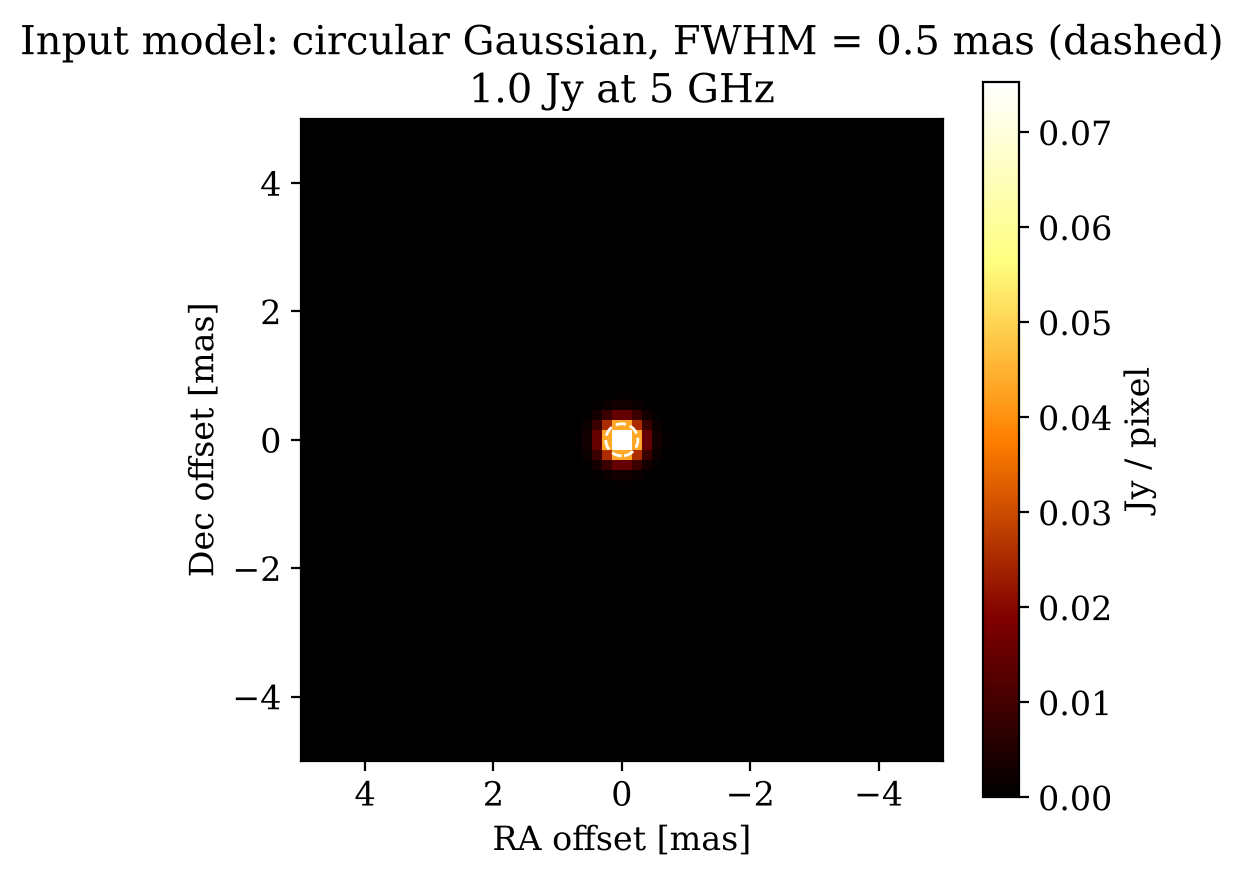

In [3]:
flux_jy = 1.0                            # source flux density at 5 GHz [Jy]
src_fwhm_mas = 0.5                       # FWHM of the circular Gaussian [mas]
src_ra_h, src_dec_deg = 12.0, 4.0        # source position (as in the 5 GHz hands-on)
npix_model, fov_model = 64, 10*mas       # model grid: 64 pixels over 10 mas

im_src = eh.image.make_empty(npix_model, fov_model, src_ra_h, src_dec_deg, rf=nu, source='GaussSrc', mjd=58849,
                             pulse=eh.observing.pulses.deltaPulse2D)
im_src = im_src.add_gauss(flux_jy, [src_fwhm_mas*mas, src_fwhm_mas*mas, 0, 0, 0])
im_src.rf = nu                           # (u,v) are computed from THIS frequency
gauss_amp = lambda rho: flux_jy*np.exp(-(np.pi*src_fwhm_mas*mas*rho)**2/(4*np.log(2)))   # analytic |V|(uv-distance)
print(f"RA = {im_src.ra:.2f} h, Dec = {im_src.dec:.1f} deg, S = {im_src.total_flux():.2f} Jy, rf = {im_src.rf/1e9:.1f} GHz, "
      f"pixel = {im_src.psize/eh.RADPERUAS:.0f} uas")

half = im_src.fovx()/2/mas
fig, ax = plt.subplots(figsize=(5.2, 4.6))
h = ax.imshow(im_src.imvec.reshape(im_src.ydim, im_src.xdim), cmap='afmhot', extent=[half, -half, -half, half])
ax.add_patch(plt.Circle((0, 0), src_fwhm_mas/2, fill=False, ls='--', lw=1, color='w'))
ax.set(title=f'Input model: circular Gaussian, FWHM = {src_fwhm_mas} mas (dashed)\n{im_src.total_flux():.1f} Jy at {nu/1e9:.0f} GHz',
       xlabel='RA offset [mas]', ylabel='Dec offset [mas]')
plt.colorbar(h, label='Jy / pixel'); plt.tight_layout(); save_fig(fig, '01_input_model'); plt.show()

## 3. Reference observation (no errors) and uv-coverage

**Observing window.** As in the LBA notebook, the cell counts the visibilities per hour over a full day and picks the `obs_hours` = 6 h window with the most data (times are UTC on the observing date of the model; windows that cross midnight are allowed).

**Reference observation.** Not one of the scenarios: it is the error-free reference against which A, B and C are compared.

> **Exact Fourier transform for the simulated data.** All the simulated datasets are computed with the exact DFT (`ttype='direct'`), while self-calibration and imaging use the faster FFT (`ttype='fast'`). With a median SNR of several hundred on these baselines, the small interpolation error of the FFT would otherwise be a systematic error in the simulated data larger than the thermal noise, and no image could fit the data to within the noise.

> **Note on `add_all()`. Unlike the LBA notebook (7 stations), the closure tables are **not** pre-computed with `obs.add_all()` here: with 20 stations (1140 triangles per scan) they take more than 1 GB per dataset, and every copy made by self-calibration duplicates them, which exhausts the memory of a Colab session. The imager builds the closure quantities it needs itself, so the results are the same. `obs.add_scans()` is still called, because self-calibration with `scan_solutions=True` needs it. Each scan of `tint` = 120 s gives one visibility per baseline, so `avg_time` = 30 s has no effect on these data. For the uv-coverage figure the same observation is also simulated with the EVN alone (it is not used afterwards). The visibility at $(-u,-v)$ is the conjugate of the one at $(u,v)$, so both points are plotted.

Visibility rows per UTC hour (0..23 h): [1066 1140 1084 1026 1026  972 1026 1026  904  242   27    0    0    0
    0    0    0    0    0    0    0    2   66  626]
Selected window: 0 - 6 h UTC (6314 rows in 10-min sampling)


EVN + AVN + SKA-Mid: 6314 visibility rows, 190 baselines with data | EVN alone (no SKA): 1742 rows


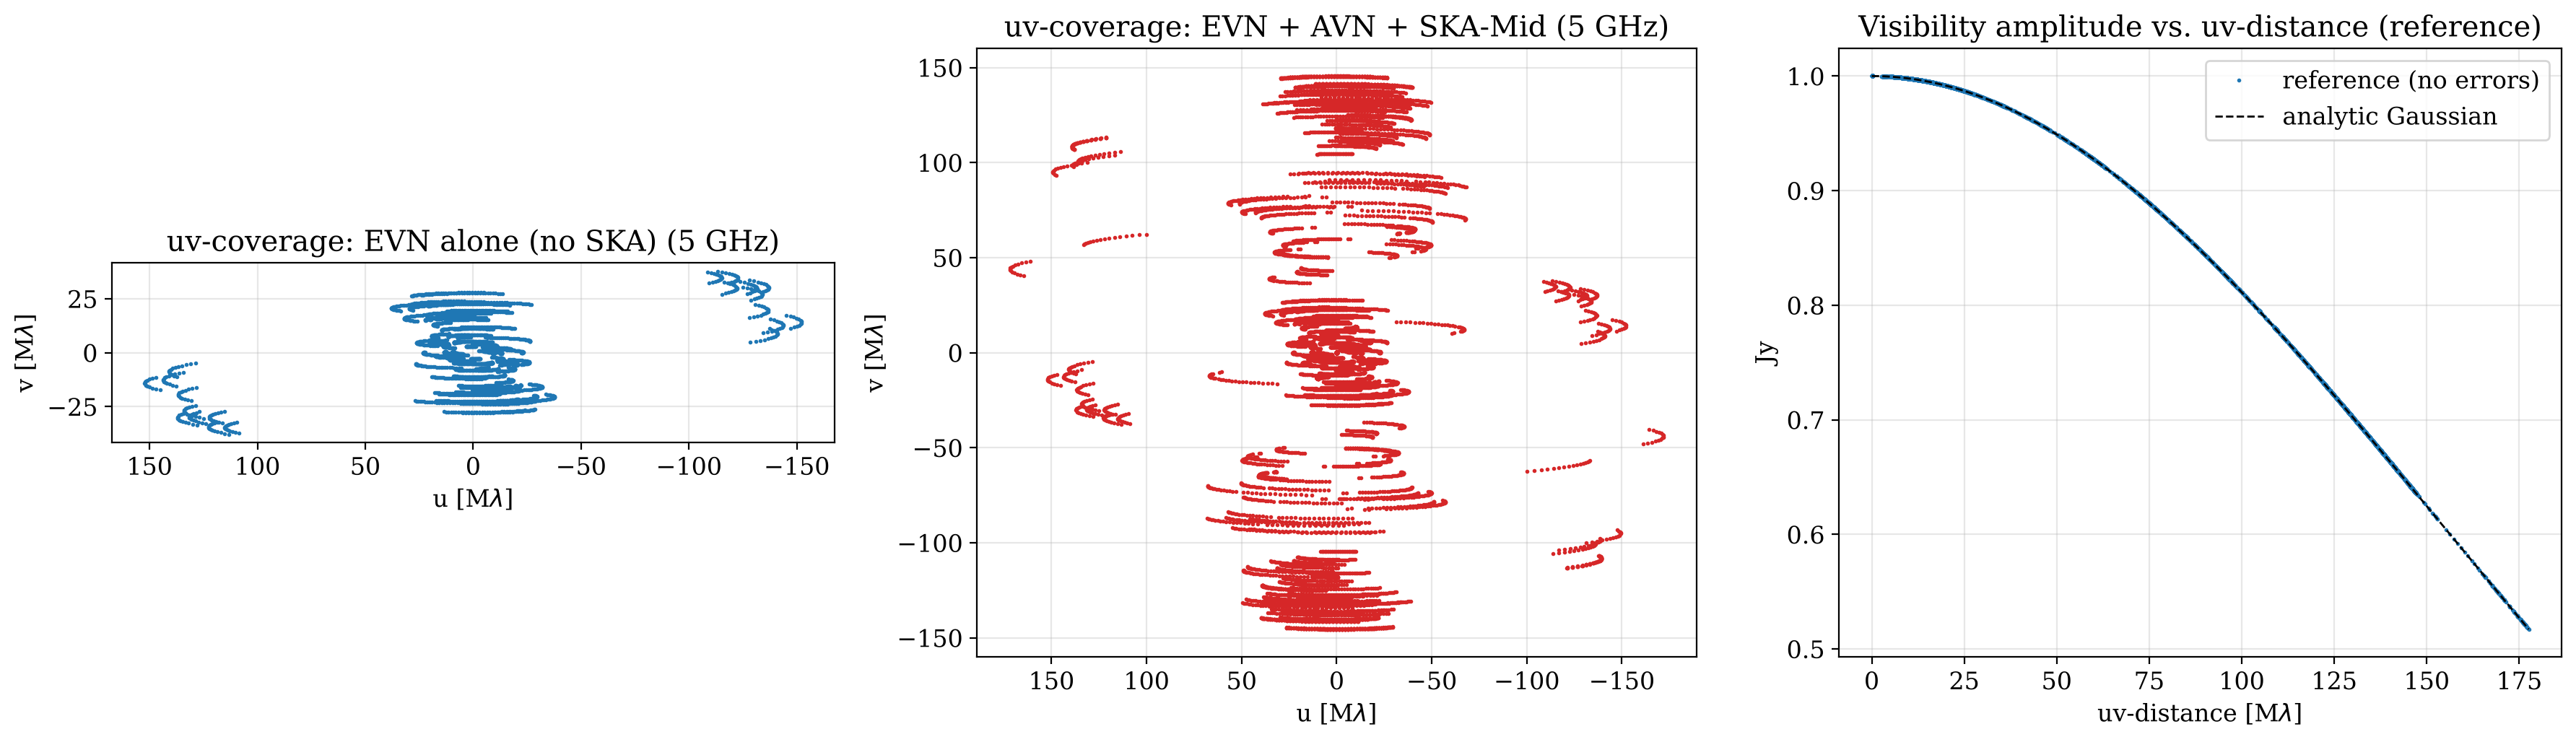

Longest projected baseline: 178 Mlambda (10646 km) -> 1/uvmax = 1.16 mas
Mean |V| on the shortest / longest 10% of the baselines: 0.999 / 0.624 Jy (100% / 62% of the total flux: the rest is resolved out)


In [4]:
def rows_per_hour(im, array, bw, elevmin=10.0):
    # number of visibility rows per UTC hour over a full day (cheap: 'fast' FT, one scan every 10 min)
    with silent():
        o = im.observe(array, 120, 600, 0, 24, bw, sgrscat=False, ttype='fast', elevmin=elevmin,
                       add_th_noise=False, ampcal=True, phasecal=True, verbose=False)
    n = np.zeros(24, int)
    for t in o.data['time']: n[int(t) % 24] += 1
    return n

counts = rows_per_hour(im_src, array_comb, bw, elevation_min)
tot = [sum(counts[(h+k) % 24] for k in range(obs_hours)) for h in range(24)]
tstart = float(int(np.argmax(tot))); tstop = tstart + obs_hours      # ehtim accepts times above 24 h
print('Visibility rows per UTC hour (0..23 h):', counts)
print(f"Selected window: {tstart:.0f} - {tstop:.0f} h UTC ({max(tot)} rows in 10-min sampling)")

obs_ideal = im_src.observe(array_comb, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='direct',
                           elevmin=elevation_min, add_th_noise=False, ampcal=True, phasecal=True, verbose=False)
obs_evn = im_src.observe(array_evn, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='direct',
                         elevmin=elevation_min, add_th_noise=False, ampcal=True, phasecal=True, verbose=False)
n_bl = len(set(zip(obs_ideal.data['t1'], obs_ideal.data['t2'])))
print(f"EVN + AVN + SKA-Mid: {len(obs_ideal.data)} visibility rows, {n_bl} baselines with data | EVN alone (no SKA): {len(obs_evn.data)} rows")

uv_ideal = np.hypot(obs_ideal.data['u'], obs_ideal.data['v'])
fig, ax = plt.subplots(1, 3, figsize=(18, 5.3))
for a, o, c, t in ((ax[0], obs_evn, 'tab:blue', 'EVN alone (no SKA)'), (ax[1], obs_ideal, 'tab:red', 'EVN + AVN + SKA-Mid')):
    a.plot(o.data['u']/1e6, o.data['v']/1e6, '.', ms=2, color=c); a.plot(-o.data['u']/1e6, -o.data['v']/1e6, '.', ms=2, color=c)
    a.set(title=f'uv-coverage: {t} ({nu/1e9:.0f} GHz)', xlabel=r'u [M$\lambda$]', ylabel=r'v [M$\lambda$]', aspect='equal')
    a.invert_xaxis(); a.grid(alpha=.3)
rr = np.linspace(0, uv_ideal.max(), 300)
ax[2].plot(uv_ideal/1e6, np.abs(obs_ideal.data['vis']), '.', ms=2, color='tab:blue', label='reference (no errors)')
ax[2].plot(rr/1e6, gauss_amp(rr), 'k--', lw=1, label='analytic Gaussian')
ax[2].set(title='Visibility amplitude vs. uv-distance (reference)', xlabel=r'uv-distance [M$\lambda$]', ylabel='Jy')
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); save_fig(fig, '02_uvcoverage_and_reference_amplitudes'); plt.show()

short, long_ = uv_ideal < np.percentile(uv_ideal, 10), uv_ideal > np.percentile(uv_ideal, 90)
amp_i = np.abs(obs_ideal.data['vis'])
print(f"Longest projected baseline: {uv_ideal.max()/1e6:.0f} Mlambda ({uv_ideal.max()*2.998e8/nu/1e3:.0f} km) -> 1/uvmax = {1/uv_ideal.max()/mas:.2f} mas")
print(f"Mean |V| on the shortest / longest 10% of the baselines: {amp_i[short].mean():.3f} / {amp_i[long_].mean():.3f} Jy "
      f"({100*amp_i[short].mean()/flux_jy:.0f}% / {100*amp_i[long_].mean()/flux_jy:.0f}% of the total flux: the rest is resolved out)")

**Baselines and closure triangles with signal.** The cell below counts the baselines whose median SNR (noise-free amplitude over the thermal-noise `sigma`) exceeds 5, and the closure triangles with all three legs above that threshold. These are the data the closure-based imaging can actually use.

In [5]:
snr = {}
for b in sorted(set(zip(obs_ideal.data['t1'], obs_ideal.data['t2']))):
    m = (obs_ideal.data['t1'] == b[0]) & (obs_ideal.data['t2'] == b[1])
    snr[b] = np.median(np.abs(obs_ideal.data['vis'][m])/obs_ideal.data['sigma'][m])
site_list = list(array_comb.tarr['site'])
leg = lambda a, b: snr.get((a, b), snr.get((b, a), 0.0))
tri = list(itertools.combinations(site_list, 3))
good = [t for t in tri if all(leg(x, y) > 5 for x, y in ((t[0], t[1]), (t[1], t[2]), (t[0], t[2])))]
print(f"Baselines with median SNR > 5: {sum(v > 5 for v in snr.values())}/{len(snr)} (out of {len(site_list)*(len(site_list)-1)//2} possible)")
print(f"Closure triangles with SNR > 5 on all three baselines: {len(good)}/{len(tri)}")
print(f"Median SNR of the reference visibilities: {np.median(np.abs(obs_ideal.data['vis'])/obs_ideal.data['sigma']):.0f}")

Baselines with median SNR > 5: 190/190 (out of 190 possible)
Closure triangles with SNR > 5 on all three baselines: 1140/1140
Median SNR of the reference visibilities: 834


## 4. Scenario A: thermal noise only

Stations are perfectly calibrated; the only corruption is receiver thermal noise, set by the SEFDs of Section 1.

In [6]:
obs_A = im_src.observe(array_comb, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='direct', verbose=False,
                       elevmin=elevation_min, add_th_noise=True, ampcal=True, phasecal=True, seed=1)
obs_A.add_scans()
print(f"Scenario A: {len(obs_A.data)} rows | median SNR = {np.median(np.abs(obs_A.data['vis'])/obs_A.data['sigma']):.1f}")

Scenario A: 6314 rows | median SNR = 834.2


## 5. Scenario B: thermal noise + gain errors + generic phase errors

Gain errors (`gain_offset`, `gainp`) and `phasecal=False`, so `ehtim` adds its own random, independent per-timestamp, per-station phase.

In [7]:
obs_B = im_src.observe(array_comb, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='direct', verbose=False,
                       elevmin=elevation_min, add_th_noise=True,
                       ampcal=False, gain_offset=gain_offset_val, gainp=gainp_val,
                       phasecal=False, seed=2)
obs_B.add_scans()
print(f"Scenario B: {len(obs_B.data)} rows")

Scenario B: 6314 rows


## 6. Scenario C: thermal noise + gain errors + structured atmospheric corruptions (ionospheric + tropospheric)

Same noise and gain budget as B, but `phasecal=True` (no `ehtim` phase noise); the phase errors come from **atmospheric corruptions** with two parts: an **ionospheric** one (dispersive, set by the dTEC) and a **tropospheric** one (non-dispersive delay, which also absorbs clock errors). Per station $i$:

$$\phi_i(t,\nu)=\frac{K\,\mathrm{dTEC}_i(t)}{\nu}+2\pi\nu\,\tau_i(t),\qquad K=8.448\times10^{9}\ \mathrm{rad\,Hz/TECU}.$$

Each part has a static per-station offset plus a random walk (TECU/√min for the ionospheric dTEC, ns/√min for the tropospheric delay), and each visibility is multiplied by $\Gamma_{ij}=\langle e^{i(\phi_i-\phi_j)}\rangle$ averaged over `n_chan` channels across the band and over sub-integrations of the 2-min scan. $\Gamma_{ij}$ is **not antenna-based**, so self-cal and closure quantities cannot fully remove the part of it that varies within the band or the scan. The thermal noise is added *after* the atmospheric corruptions so that the decorrelation attenuates the signal but not the noise.

**The same parameters of the atmospheric corruptions (ionospheric and tropospheric) as in the 250 MHz LBA notebook are used**, so that the comparison isolates the effect of the observing frequency:

* **Dispersive (ionospheric) term:** at 5 GHz, 1 TECU is only **1.7 rad** (33.8 rad at 250 MHz) and the dispersive phase changes by ~0.09 rad per TECU across the 256 MHz band, so the ionosphere is a small, almost antenna-based phase at C-band.
* **Non-dispersive (tropospheric) delay term:** grows with frequency. A 0.5 ns delay is 15.7 rad at 5 GHz, and a delay *difference* between two stations produces a phase slope of $2\pi\,\Delta\tau\,\Delta\nu$ across the band (0.8 rad for 0.5 ns over 256 MHz), plus a phase drift within the scan from the delay random walk. At 5 GHz the in-band and in-scan decorrelation of scenario C is therefore dominated by the **delay** (tropospheric) term, not by the ionosphere.

**Fringe fitting.** At C-band, real VLBI data are *fringe-fitted* before imaging: a delay and a rate are solved per station and scan and removed. The pipeline of this notebook (like the one of the LBA notebook) has no fringe-fit step, so scenario C contains the full tropospheric delay screen (and the ionospheric dTEC screen). To show how much of it a fringe fit would remove, the cell also builds `obs_Cff`: the same scenario C after an **idealised fringe fit** (the scan-average delay and dTEC and their linear drift within the scan are removed per baseline before the averaging), which keeps only the non-linear wander of the ionospheric and tropospheric screens within each scan. It is imaged once in Section 8 as an extra reference; it is not a fourth scenario.

The `dtec0_sigma`, `dtec_rate`, `tau0_sigma_ns` and `tau_rate_ns` values are illustrative, not measured; vary them.

In [8]:
K = 8.4479745e9   # rad Hz / TECU

def make_screens(sites, t0_h, t1_h, dtec0_sigma=0.3, dtec_rate=0.02,
                 tau0_sigma_ns=0.5, tau_rate_ns=0.01, dt_s=10.0, seed=42):
    # dtec0_sigma [TECU]: static offset; dtec_rate [TECU/sqrt(min)]: random-walk rate (same for the delay, in ns).
    rng = np.random.default_rng(seed)
    n = len(sites); ng = int(np.ceil((t1_h - t0_h)*3600/dt_s)) + 2
    tg = t0_h + np.arange(ng)*dt_s/3600.0
    s = np.sqrt(dt_s/60.0)
    dtec = dtec0_sigma*rng.normal(size=(n, 1))   + np.cumsum(rng.normal(0, dtec_rate*s,   (n, ng)), axis=1)
    tau  = tau0_sigma_ns*rng.normal(size=(n, 1)) + np.cumsum(rng.normal(0, tau_rate_ns*s, (n, ng)), axis=1)
    return {'sites': list(sites), 't': tg, 'dtec': dtec, 'tau_ns': tau}

def apply_iono(obs, scr, nu0, bw, n_chan=32, tint=120.0, n_sub=24, add_noise=True, seed=3, decorrelate=True, fringefit=False):
    # Multiplies every visibility by Gamma_ij = <exp(i(phi_i - phi_j))> over n_chan channels x n_sub sub-integrations.
    # fringefit=True: idealised fringe fit, i.e. the scan-average delay, dTEC and their linear drift (rate) within the scan
    # are removed per baseline before averaging, so only the non-linear in-scan wander is left.
    out = obs.copy(); d = out.data
    idx = {s: i for i, s in enumerate(scr['sites'])}
    i1 = np.array([idx[s] for s in d['t1']]); i2 = np.array([idx[s] for s in d['t2']])
    nuc = nu0 + (np.arange(n_chan) - (n_chan-1)/2)*bw/n_chan if decorrelate else np.array([nu0])
    sub = ((np.arange(n_sub) if decorrelate else np.array([(n_sub-1)/2])) - (n_sub-1)/2)*tint/n_sub/3600.0
    tt = d['time'][:, None] + sub[None, :]                                   # (rows, n_sub)
    def phase(i, field, scale):
        return np.array([np.interp(tt[k], scr['t'], scr[field][i[k]]) for k in range(len(d))])*scale
    dd = phase(i1, 'dtec', 1.0) - phase(i2, 'dtec', 1.0)                     # dTEC difference [TECU], (rows, n_sub)
    dt = phase(i1, 'tau_ns', 1e-9) - phase(i2, 'tau_ns', 1e-9)               # delay difference [s]
    if fringefit:
        x = sub - sub.mean()
        detrend = lambda y: y - y.mean(1, keepdims=True) - np.outer((y*x).sum(1)/(x**2).sum(), x)
        dd, dt = detrend(dd), detrend(dt)
    ph = K*dd[:, None, :]/nuc[None, :, None] + 2*np.pi*nuc[None, :, None]*dt[:, None, :]   # (rows, chan, sub)
    G = np.exp(1j*ph).mean(axis=(1, 2))
    for c in d.dtype.names:
        if c.endswith('vis'): d[c] = d[c]*G
    if add_noise:
        rng = np.random.default_rng(seed)
        for c, sg in (('vis', 'sigma'), ('qvis', 'qsigma'), ('uvis', 'usigma'), ('vvis', 'vsigma')):
            d[c] = d[c] + rng.normal(0, d[sg]) + 1j*rng.normal(0, d[sg])
    return out, G

# base: gain errors, NO thermal noise, NO ehtim phase errors
obs_C0 = im_src.observe(array_comb, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='direct', verbose=False,
                        elevmin=elevation_min, add_th_noise=False,
                        ampcal=False, gain_offset=gain_offset_val, gainp=gainp_val, phasecal=True, seed=4)
scr = make_screens(array_comb.tarr['site'], tstart, tstop)
obs_C, G = apply_iono(obs_C0, scr, nu, bw, n_chan=n_chan, tint=tint)
obs_C.add_scans()
print(f"Scenario C: {len(obs_C.data)} rows | |G| mean = {np.mean(np.abs(G)):.3f}, min = {np.abs(G).min():.3f} (1 = no decorrelation)")
print(f"Phase per TECU at {nu/1e9:.0f} GHz: {K/nu:.2f} rad (33.8 rad at 250 MHz) | change across the band: {K/(nu-bw/2)-K/(nu+bw/2):.3f} rad/TECU")
print(f"Phase per ns of delay at {nu/1e9:.0f} GHz: {2*np.pi*nu*1e-9:.1f} rad | phase slope across the band: {2*np.pi*bw*1e-9:.2f} rad/ns")
# Which term decorrelates? Repeat with only one of the two terms switched on
scr_d = dict(scr, tau_ns=0*scr['tau_ns']); scr_t = dict(scr, dtec=0*scr['dtec'])
_, G_d = apply_iono(obs_C0, scr_d, nu, bw, n_chan=n_chan, tint=tint, add_noise=False)
_, G_t = apply_iono(obs_C0, scr_t, nu, bw, n_chan=n_chan, tint=tint, add_noise=False)
print(f"Mean |G| with the dTEC term only: {np.mean(np.abs(G_d)):.4f} | with the delay term only: {np.mean(np.abs(G_t)):.4f}")

# Same atmospheric corruptions (ionospheric + tropospheric) after an idealised fringe fit (scan-average delay/dTEC and rate removed): see the text above
obs_Cff, G_ff = apply_iono(obs_C0, scr, nu, bw, n_chan=n_chan, tint=tint, fringefit=True)
obs_Cff.add_scans()
print(f"After an idealised fringe fit: |G| mean = {np.mean(np.abs(G_ff)):.4f}, min = {np.abs(G_ff).min():.4f}")

Scenario C: 6314 rows | |G| mean = 0.920, min = 0.524 (1 = no decorrelation)
Phase per TECU at 5 GHz: 1.69 rad (33.8 rad at 250 MHz) | change across the band: 0.087 rad/TECU
Phase per ns of delay at 5 GHz: 31.4 rad | phase slope across the band: 1.61 rad/ns


Mean |G| with the dTEC term only: 0.9995 | with the delay term only: 0.9205


After an idealised fringe fit: |G| mean = 0.9893, min = 0.9255


## 7. Self-calibration (oracle reference) and closure check

The self-calibration in the first cell uses the **true model** (an *oracle*): it is a best-case reference and is **not** used by `pipeline_3rounds`, which self-calibrates to its own previous image (Section 8). The visibilities of a centred circular Gaussian are real and positive, so its true closure phases are zero. Antenna-based gain and phase errors cancel in closure phases, so in A and B the closure-phase residual reflects thermal noise only, while in C the non-antenna-based decorrelation can add extra scatter. The cell also checks that a pure phase screen (no decorrelation, no noise) leaves the closure phases unchanged, and reports the reduced $\chi^2$ of the oracle self-calibrated data against the true model.

`self_cal` solves one complex gain per station and scan (`scan_solutions=True`, which needs `obs.add_scans()`), with `ttype='fast'`; each call takes about a minute with this array.

In [9]:
t0 = time.time()
with contextlib.redirect_stdout(io.StringIO()):
    cal_B_oracle = sc.self_cal(obs_B, im_src, ttype='fast', scan_solutions=True, processes=1)
    cal_C_oracle = sc.self_cal(obs_C, im_src, ttype='fast', scan_solutions=True, processes=1)
print(f"Oracle self-calibration of B and C: {time.time()-t0:.0f} s")

def cphase_table(obs):
    cp = obs.c_phases(vtype='vis', mode='all', count='min', ang_unit='deg')
    return {(round(float(r['time']), 5), r['t1'], r['t2'], r['t3']): (float(r['cphase']), float(r['sigmacp'])) for r in cp}
cp_ref = cphase_table(obs_ideal)

def cphase_resid(obs):
    # residual closure phase w.r.t. the noise-free reference, wrapped to [-180, 180) deg, and normalised by its sigma
    t = cphase_table(obs); keys = [k for k in t if k in cp_ref]
    r = np.array([(t[k][0] - cp_ref[k][0] + 180) % 360 - 180 for k in keys]); s = np.array([t[k][1] for k in keys])
    return r, s

with contextlib.redirect_stdout(io.StringIO()):
    obs_Cp, _ = apply_iono(obs_C0, scr, nu, bw, add_noise=False, decorrelate=False)   # phase screen only
    r0 = np.array([(a[0]-b[0]+180) % 360 - 180 for a, b in zip(cphase_table(obs_Cp).values(), cphase_table(obs_C0).values())])
print(f"Phase screen only: max |change in closure phase| = {np.abs(r0).max():.1e} deg (antenna-based errors cancel exactly)")
cp_resid = {}
for name, o in (('A', obs_A), ('B', obs_B), ('C', obs_C)):
    with contextlib.redirect_stdout(io.StringIO()):
        r, s = cphase_resid(o)
    cp_resid[name] = (r, s)
    print(f"Scenario {name}: closure-phase residual rms = {np.sqrt(np.mean(r**2)):6.2f} deg, "
          f"rms(residual/sigma) = {np.sqrt(np.mean((r/s)**2)):.2f}  ({len(r)} closure phases)")
for name, o in (('B oracle self-cal', cal_B_oracle), ('C oracle self-cal', cal_C_oracle)):
    with contextlib.redirect_stdout(io.StringIO()):
        chi = o.chisq(im_src, dtype='vis', ttype='fast')
    print(f"{name}: reduced chi^2 of the complex visibilities against the true model = {chi:.2f}")

Oracle self-calibration of B and C: 95 s


Phase screen only: max |change in closure phase| = 8.2e-13 deg (antenna-based errors cancel exactly)


Scenario A: closure-phase residual rms =   0.11 deg, rms(residual/sigma) = 1.00  (5658 closure phases)


Scenario B: closure-phase residual rms =   0.11 deg, rms(residual/sigma) = 1.01  (5658 closure phases)


Scenario C: closure-phase residual rms =   0.27 deg, rms(residual/sigma) = 6.11  (5658 closure phases)


B oracle self-cal: reduced chi^2 of the complex visibilities against the true model = 0.91


C oracle self-cal: reduced chi^2 of the complex visibilities against the true model = 3213.42


## 8. Imaging: closure quantities vs. raw visibilities

The imaging uses `ehtim`'s regularized-maximum-likelihood (RML) imager in several rounds. `run_pipeline` adds **iterative self-calibration**: before a round marked `'selfcal'`, the *raw* data are self-calibrated to the image reconstructed so far (never to the true model).

**Reconstruction grid.** `npix_rec` = 64 pixels over `fov_beams` = 10 nominal beams (~10 mas, ~0.15 mas pixels, about 6 pixels per nominal beam, as in the LBA notebook). **Prior:** a Gaussian of one nominal beam FWHM, a source-agnostic choice; a prior much larger than the resolution can keep a closure-only first round from converging.

**Regularizer weights and iterations** (`w_simple`, `w_tv`, `w_flux`, `maxit_rounds`, set below for this source and grid). The median SNR of these data is several hundred, so the reduced $\chi^2$ of the data terms starts in the thousands and dominates the objective function. Closure phases and closure amplitudes do not constrain the total flux, and with the flux weight of the LBA notebook (`flux` = 1000) a closure-only first round lets the total flux run away (to ~3.5 Jy for the jet in our tests); a weight of 10⁵ keeps it at the known total flux `zbl` (in a real observation, measured on the shortest baselines or with a single dish). For this compact source the entropy and TV weights of the LBA notebook (`w_simple` = 100, `w_tv` = 10) and its iterations (100, 150 and 150 per round) are kept.

**`pipeline_3rounds`** is the single pipeline used for A, B and C (the same structure as in the LBA notebook):
1. Round 1 fits only gain-invariant closure quantities (`cphase`, `logcamp`) on the raw data.
2. The raw data are self-calibrated to the round-1 image (`selfcal_round2`: amplitude and phase for the compact source, as in the LBA notebook; **phase only** for the jet, see below); round 2 fits the bispectrum and the visibility amplitudes.
3. The raw data are self-calibrated again to the round-2 image; round 3 refines with total variation.

`pipeline_oracle` has the same structure but self-calibrates to the true model (best case). `closure_rounds_handson` is the closure-based imaging strategy of the `ehtim` hands-on (bispectrum → amplitudes + closure phases → closure quantities on the oracle-calibrated data), run as a reference; `vis_rounds` fits the raw complex visibilities with no calibration at all (expected to fail with gain and phase errors).

**Final restoring beam.** The data constrain nothing below the resolution of the array, so each final image is blurred once, at the end, with a Gaussian equal to the **fitted dirty beam** (`obs.fit_beam`, uniform weighting by default; `beam_weighting = 'natural'` gives a broader, more conservative beam). This beam is elliptical and larger than the nominal `1/uvmax` resolution, which is only the best case along the longest baseline. The metrics compare the restored reconstruction with the true model restored with the same beam. The blur between rounds (`blur_frac`) is a separate imaging setting.

Besides the three scenarios, the cell runs the references of the table above and `pipeline_3rounds` on the idealised fringe-fitted scenario C (`obs_Cff`, Section 6): 8 reconstructions in total, each pipeline run including two self-calibrations. Expect ~15–30 min on a laptop or in Colab.

In [10]:
def run_rml_imager(obs, prior, flux, rounds, ttype='fast', verbose=False, obs_alt=None, history=None):
    # If `history` is a list, the reduced chi^2 of each data term is appended to it at every iteration.
    imgr = None; out = prior; current_obs = obs
    for i, rnd in enumerate(rounds):
        key = rnd.get('switch_obs')
        if key is not None and obs_alt and key in obs_alt:
            current_obs = obs_alt[key]
            if verbose: print(f"  -> Round {i+1}/{len(rounds)}: switching obs to '{key}', data_term={list(rnd['data_term'])}")
        elif verbose:
            print(f"  -> Round {i+1}/{len(rounds)}: data_term={list(rnd['data_term'])}")
        blur_frac = rnd.get('blur_frac', 0.0)
        init_im = out.blur_circ(blur_frac*current_obs.res()) if blur_frac > 0 else out
        if imgr is None:
            Imgr = LoggedImager if history is not None else eh.imager.Imager
            with silent():
                imgr = Imgr(current_obs, init_im, init_im, flux, data_term=rnd['data_term'],
                            reg_term=rnd['reg_term'], maxit=rnd['maxit'], ttype=ttype)
            imgr.history = history
        else:
            imgr.obslist_next = [current_obs]; imgr.init_next = init_im; imgr.prior_next = init_im
            imgr.dat_term_next = rnd['data_term']; imgr.reg_term_next = rnd['reg_term']; imgr.maxit_next = rnd['maxit']
        imgr.round_id = i
        plt.ioff()
        with contextlib.redirect_stdout(io.StringIO()):
            out = imgr.make_image_I(show_updates=False)
        plt.close('all'); plt.ion()
    return out

class LoggedImager(eh.imager.Imager):
    # Imager that records the reduced chi^2 of every active data term at each iteration (iteration 0 = initial image).
    def plotcur(self, imvec, **kwargs):
        if getattr(self, 'history', None) is not None:
            chi2 = self.make_chisq_dict(np.exp(imvec))          # the optimizer works on the log-image
            self.history.append({'round': self.round_id, 'iter': self._nit, **{k: float(v) for k, v in chi2.items()}})
        super().plotcur(imvec, **kwargs)

CHI2_COLORS = {'cphase': 'tab:blue', 'logcamp': 'tab:orange', 'bs': 'tab:green', 'amp': 'tab:red', 'vis': 'tab:purple'}

def plot_chi2_histories(hists, fname, title, ncols=4):
    # One panel per reconstruction: reduced chi^2 of every active data term at every iteration (cumulative over the
    # rounds; dashed lines = start of a new round, dotted line = chi^2 of 1).
    keys = [k for k in hists if hists[k]]
    nrows = int(np.ceil(len(keys)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.7*ncols, 3.7*nrows), squeeze=False)
    for ax, k in zip(axes.ravel(), keys):
        h = hists[k]; off = 0; edges = []; seen = set()
        for r in sorted({x['round'] for x in h}):
            rec = [x for x in h if x['round'] == r]
            xs = off + np.array([x['iter'] for x in rec])
            for t, c in CHI2_COLORS.items():
                if t in rec[0]:
                    ax.semilogy(xs, [x[t] for x in rec], color=c, lw=1.4, label=None if t in seen else t); seen.add(t)
            off = xs.max() + 1; edges.append(off)
        for e in edges[:-1]: ax.axvline(e, color='gray', ls='--', lw=0.8)
        ax.axhline(1, color='k', ls=':', lw=0.8)
        ax.set_title(k if isinstance(k, str) else f'{k[1]}: {k[0]}', fontsize=9)
        ax.set_xlabel('iteration (cumulative over rounds)', fontsize=8); ax.legend(fontsize=7, loc='upper right')
    for ax in axes.ravel()[len(keys):]: ax.axis('off')
    for ax in axes[:, 0]: ax.set_ylabel(r'reduced $\chi^2$')
    fig.suptitle(title, fontsize=12); plt.tight_layout(); save_fig(fig, fname); plt.show()

def run_pipeline(obs, prior, flux, rounds, ttype='fast', model=None, final_beam=None, history=None):
    # Like run_rml_imager, but a round with 'selfcal' in {'phase','both'} first self-calibrates the RAW data
    # to the image obtained so far; 'oracle' self-calibrates to `model` (the true image) instead.
    # If `final_beam` = [major, minor, PA] [rad] is given, the final image is restored (blurred) with that Gaussian.
    # If `history` is a list, the reduced chi^2 of each data term is appended to it at every iteration.
    imgr = None; out = prior; current = obs
    for i, rnd in enumerate(rounds):
        m = rnd.get('selfcal')
        if m:
            with contextlib.redirect_stdout(io.StringIO()):
                if m == 'oracle':
                    current = sc.self_cal(obs, model, method='both', ttype=ttype, scan_solutions=True, processes=1)
                else:
                    current = sc.self_cal(obs, out, method=m, ttype=ttype, scan_solutions=True, processes=1)
        bf = rnd.get('blur_frac', 0.0)
        init_im = out.blur_circ(bf*current.res()) if bf > 0 else out
        if imgr is None:
            Imgr = LoggedImager if history is not None else eh.imager.Imager
            with silent():
                imgr = Imgr(current, init_im, init_im, flux, data_term=rnd['data_term'],
                            reg_term=rnd['reg_term'], maxit=rnd['maxit'], ttype=ttype)
            imgr.history = history
        else:
            imgr.obslist_next = [current]; imgr.init_next = init_im; imgr.prior_next = init_im
            imgr.dat_term_next = rnd['data_term']; imgr.reg_term_next = rnd['reg_term']; imgr.maxit_next = rnd['maxit']
        imgr.round_id = i
        plt.ioff()
        with contextlib.redirect_stdout(io.StringIO()):
            out = imgr.make_image_I(show_updates=False)
        plt.close('all'); plt.ion()
    if final_beam is None:
        return out
    restored = out.blur_gauss(final_beam, frac=1.0)
    restored.unrestored = out          # unrestored image, used as self-calibration model in Section 11
    return restored

w_simple, w_tv, w_flux = 100, 10, 1e5     # regularizer weights (entropy, total variation, total flux) for this grid
maxit_rounds = (100, 150, 150)            # iterations of the three rounds
w_flux_cl = w_flux                        # flux weight in closure-only rounds
selfcal_round2 = 'both'                   # self-calibration before round 2: amplitude + phase
FM = {'flux': w_flux, 'cm': 50}
FM_CL = {'flux': w_flux_cl, 'cm': 50}            # used in the rounds that fit closure quantities only
CL, BA = {'cphase': 100, 'logcamp': 50}, {'bs': 100, 'amp': 50}
closure_rounds_handson = [
    {'data_term': {'bs': 100},                'reg_term': {'simple': 10, **FM}, 'maxit': 60},
    {'data_term': {'amp': 50, 'cphase': 100}, 'reg_term': {'tv': 1,  **FM}, 'maxit': 80,  'blur_frac': 1.0},
    {'data_term': {'cphase': 100, 'logcamp': 50}, 'reg_term': {'tv': 10, **FM}, 'maxit': 100,
     'blur_frac': 0.5, 'switch_obs': 'cal'},
]
i1, i2, i3 = maxit_rounds
pipeline_3rounds = [
    {'data_term': CL, 'reg_term': {'simple': w_simple, **FM_CL}, 'maxit': i1},
    {'data_term': BA, 'reg_term': {'simple': w_simple, **FM}, 'maxit': i2, 'blur_frac': 1.0, 'selfcal': selfcal_round2},
    {'data_term': BA, 'reg_term': {'tv': w_tv, **FM},      'maxit': i3, 'blur_frac': 0.5, 'selfcal': 'both'},
]
pipeline_oracle = [
    {'data_term': {'bs': 100}, 'reg_term': {'simple': w_simple, **FM}, 'maxit': i1},
    {'data_term': BA, 'reg_term': {'simple': w_simple, **FM}, 'maxit': i2, 'blur_frac': 1.0, 'selfcal': 'oracle'},
    {'data_term': BA, 'reg_term': {'tv': w_tv, **FM},      'maxit': i3, 'blur_frac': 0.5},
]
vis_rounds = [
    {'data_term': {'vis': 100}, 'reg_term': {'simple': 10, **FM}, 'maxit': 60},
    {'data_term': {'vis': 100}, 'reg_term': {'tv': 1,      **FM}, 'maxit': 180, 'blur_frac': 1.0},
]

npix_rec, fov_beams = 64, 10             # reconstruction grid: pixels per side, FOV in nominal beams
beam = obs_A.res(); npix = npix_rec; fov = fov_beams*beam; zbl = im_src.total_flux()
prior_fwhm = beam                        # one-beam Gaussian prior
with contextlib.redirect_stdout(io.StringIO()):
    beam_params = obs_A.fit_beam(weighting=beam_weighting)      # fitted dirty beam: [major, minor, PA] in rad
print(f"Dirty beam ({beam_weighting}): {beam_params[0]/mas:.2f} x {beam_params[1]/mas:.2f} mas, PA {np.degrees(beam_params[2]):.0f} deg  (nominal 1/uvmax = {beam/mas:.2f} mas)")
empty = eh.image.make_empty(npix, fov, obs_A.ra, obs_A.dec, rf=nu, pulse=im_src.pulse)   # same pixel shape as the model
prior = empty.add_gauss(zbl, [prior_fwhm, prior_fwhm, 0, 0, 0])
print(f"FOV: {fov/mas:.1f} mas | pixel: {fov/npix/eh.RADPERUAS:.0f} uas ({beam/(fov/npix):.1f} px per nominal beam) | prior FWHM {prior_fwhm/mas:.2f} mas")

Dirty beam (uniform): 2.18 x 0.87 mas, PA 88 deg  (nominal 1/uvmax = 1.16 mas)
FOV: 11.6 mas | pixel: 182 uas (6.4 px per nominal beam) | prior FWHM 1.16 mas


In [11]:
recs = {}; t_img = time.time()
hist = {}                                         # chi^2 history (every iteration) of EVERY reconstruction
for s_, o_ in (('A', obs_A), ('B', obs_B), ('C', obs_C)):
    k_ = f'{s_}  3-round pipeline'; hist[k_] = []
    recs[k_] = run_pipeline(o_, prior, zbl, pipeline_3rounds, final_beam=beam_params, history=hist[k_])
    print(f"  scenario {s_}: pipeline_3rounds done ({time.time()-t_img:.0f} s)")
hist_pipeline = {s_: hist[f'{s_}  3-round pipeline'] for s_ in 'ABC'}
for k_ in ('C  after fringe-fit', 'C  oracle self-cal', 'C  hands-on rounds', 'B  raw visibilities', 'C  raw visibilities'):
    hist[k_] = []
recs['C  after fringe-fit']    = run_pipeline(obs_Cff, prior, zbl, pipeline_3rounds, final_beam=beam_params, history=hist['C  after fringe-fit'])
recs['C  oracle self-cal']     = run_pipeline(obs_C, prior, zbl, pipeline_oracle, model=im_src, final_beam=beam_params, history=hist['C  oracle self-cal'])
recs['C  hands-on rounds']     = run_rml_imager(obs_C, prior, zbl, closure_rounds_handson, obs_alt={'cal': cal_C_oracle},
                                                history=hist['C  hands-on rounds']).blur_gauss(beam_params, frac=1.0)
recs['B  raw visibilities']    = run_rml_imager(obs_B, prior, zbl, vis_rounds, history=hist['B  raw visibilities']).blur_gauss(beam_params, frac=1.0)
recs['C  raw visibilities']    = run_rml_imager(obs_C, prior, zbl, vis_rounds, history=hist['C  raw visibilities']).blur_gauss(beam_params, frac=1.0)
print(f"All reconstructions done in {time.time()-t_img:.0f} s")

  scenario A: pipeline_3rounds done (164 s)


  scenario B: pipeline_3rounds done (321 s)


  scenario C: pipeline_3rounds done (480 s)


All reconstructions done in 792 s


## 9. Metrics and diagnostics

The table reports, per reconstruction (all restored with the same beam, and compared with the true model restored with that beam):

* **compact flux / true:** flux within 1.5 beams of the image peak, divided by the same quantity in the restored true model;
* **peak offset [mas]:** the position of the image peak relative to the image flux centroid, compared with the same vector in the true model. Closure-based imaging does not fix the absolute position (the centre-of-mass regularizer puts the centroid at the image centre), so a shift-invariant measure is used;
* **dynamic range:** image peak over the rms of the image in the off-source region (pixels where the aligned, restored true model is below 1% of its peak);
* **total flux [Jy]** of the reconstruction (true value: 1 Jy);
* two shift-invariant fidelity scores from `ehtim` (`nrmse`: lower is better; `nxcorr`: higher is better), computed after aligning the restored true model to the reconstruction. They penalise haze and flux errors but ignore the absolute position.

For the centred Gaussian the brightest component is the whole source, so the compact-flux ratio is the fraction of the flux recovered at the right scale, and the peak offset measures any spurious displacement of the source relative to its own centroid (zero for a symmetric source).

In [12]:
truth_g = im_src.regrid_image(fov, npix).blur_gauss(beam_params, frac=1.0)   # true model on the reconstruction grid, restored with the same beam
truth_g.imvec *= zbl/truth_g.total_flux()

def peak_and_centroid(img):
    yy, xx = np.indices(img.shape); w = np.clip(img, 0, None)
    iy, ix = np.unravel_index(np.argmax(img), img.shape)
    return np.array([iy, ix]), np.array([(w*yy).sum()/w.sum(), (w*xx).sum()/w.sum()]), yy, xx

def compact_flux(img, psize):
    p, _, yy, xx = peak_and_centroid(img)
    return img[np.hypot(yy-p[0], xx-p[1])*psize < 1.5*beam].sum()

def fidelity(im):
    (xc, nr), im1, im2 = im.compare_images(truth_g, blur_frac=0.0, metric=['nxcorr', 'nrmse'])
    return float(xc), float(nr), im1, im2

T_arr = truth_g.imvec.reshape(npix, npix)
pT, cT, _, _ = peak_and_centroid(T_arr); fT = compact_flux(T_arr, truth_g.psize)

def image_metrics(im):
    img = im.imvec.reshape(im.ydim, im.xdim)
    p, c, _, _ = peak_and_centroid(img)
    off = np.hypot(*((p - c) - (pT - cT)))*im.psize/mas
    xc, nr, im1, im2 = fidelity(im)
    a1 = im1.imvec.reshape(im1.ydim, im1.xdim); a2 = im2.imvec.reshape(im2.ydim, im2.xdim)
    dr = a1.max()/a1[a2 < 0.01*a2.max()].std()
    return compact_flux(img, im.psize)/fT, off, dr, im.total_flux(), nr, xc, im1, im2

print(f"{'reconstruction':24s} {'compact/true':>13s} {'peak off.[mas]':>15s} {'dyn. range':>11s} {'flux [Jy]':>10s} {'nrmse':>7s} {'nxcorr':>7s}")
metrics_rows = []; aligned = {}
for k, im in recs.items():
    f, off, dr, ft, nr, xc, im1, im2 = image_metrics(im)
    metrics_rows.append((k, f, off, dr, ft, nr, xc)); aligned[k] = (im1, im2)
    print(f"{k:24s} {f:13.2f} {off:15.2f} {dr:11.0f} {ft:10.2f} {nr:7.2f} {xc:7.2f}")

reconstruction            compact/true  peak off.[mas]  dyn. range  flux [Jy]   nrmse  nxcorr
A  3-round pipeline               0.98            0.00        1567       0.99    0.02    1.00
B  3-round pipeline               0.99            0.00        1932       1.00    0.01    1.00
C  3-round pipeline               0.96            0.05         725       1.01    0.09    1.00
C  after fringe-fit               0.99            0.01        1729       1.00    0.02    1.00
C  oracle self-cal                0.99            0.01        2070       1.00    0.01    1.00
C  hands-on rounds                0.98            0.04        1293       1.00    0.04    1.00
B  raw visibilities               0.08            1.80          33       0.15    8.94    0.83
C  raw visibilities               0.08            2.25          29       0.14   10.11    0.79


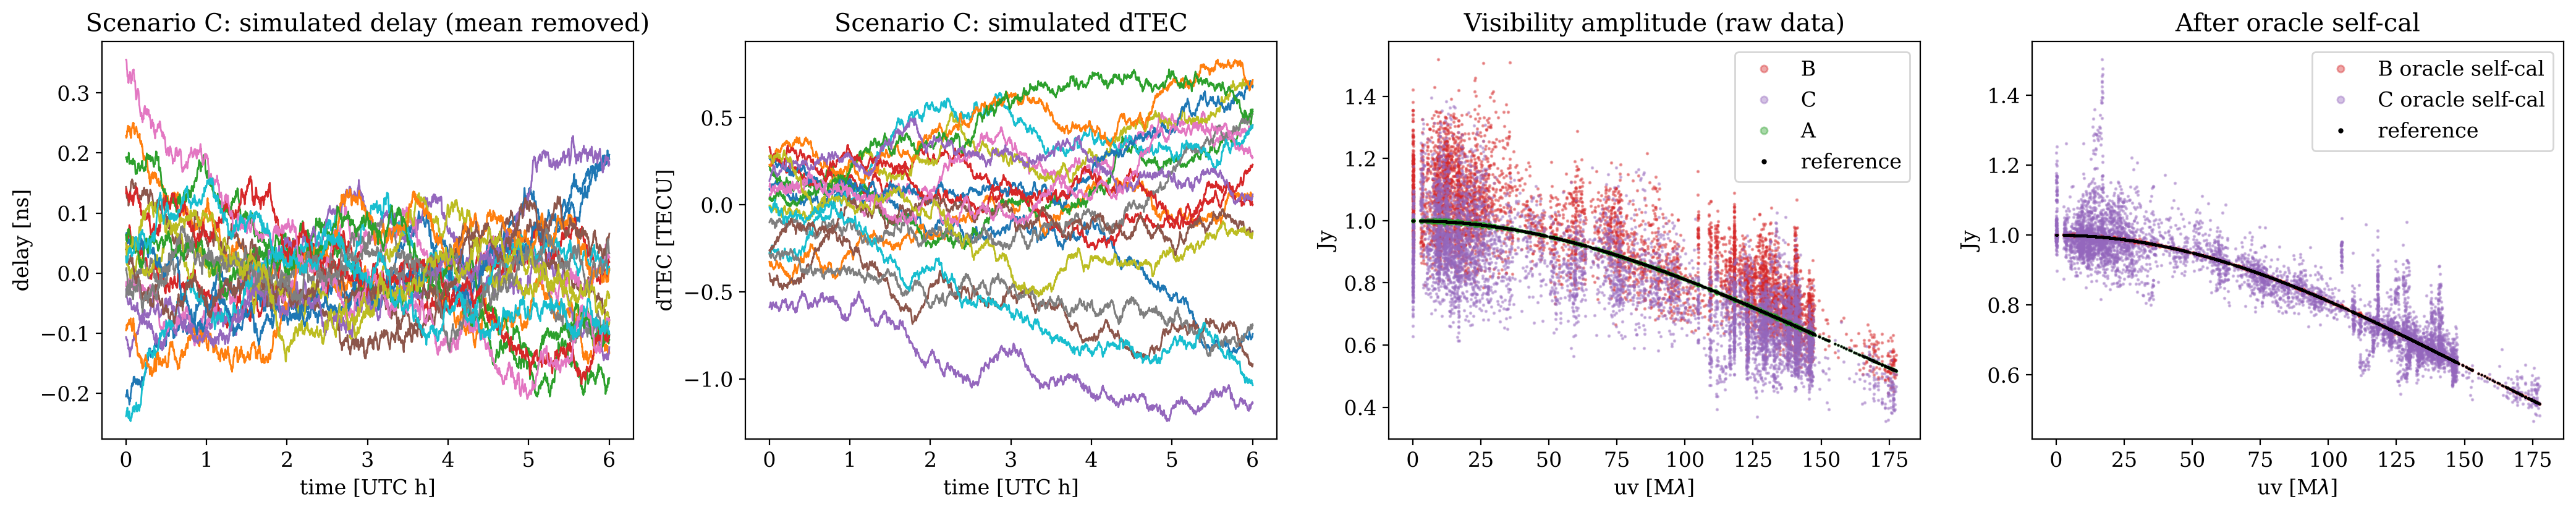

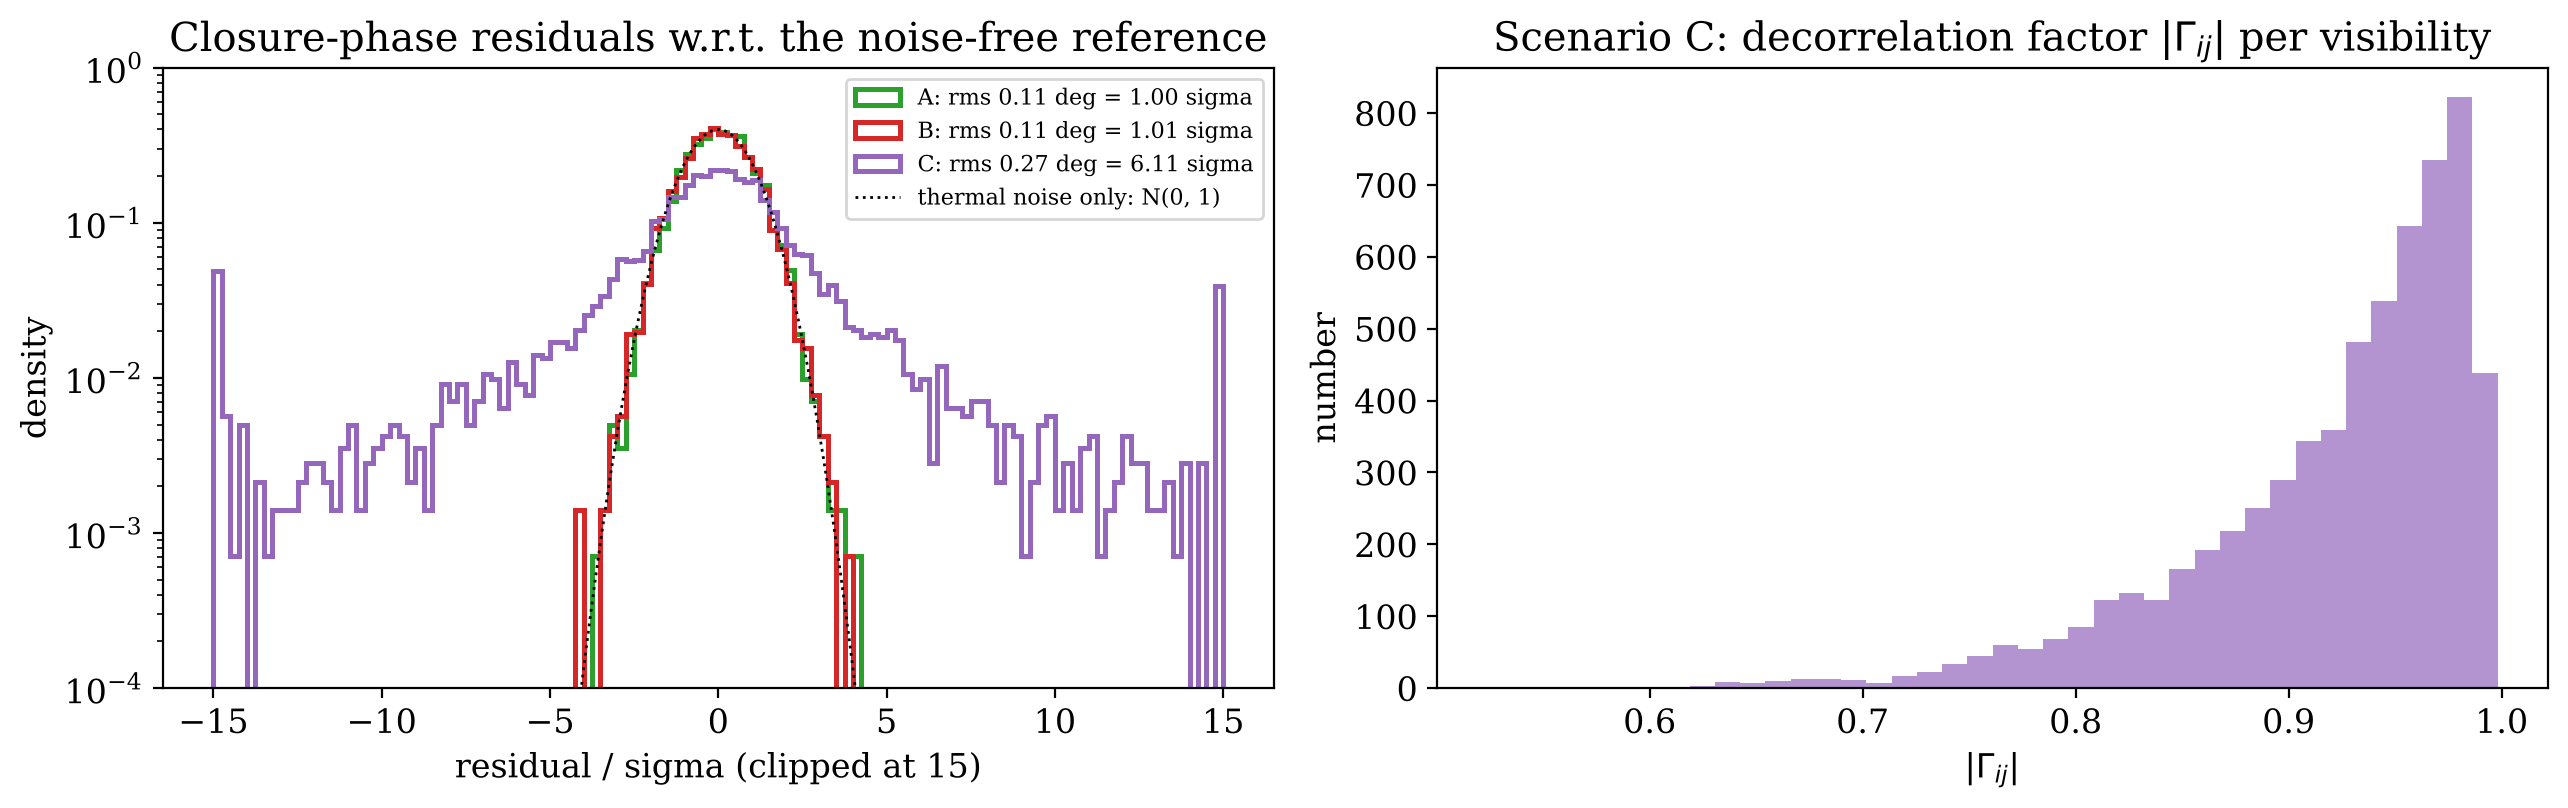

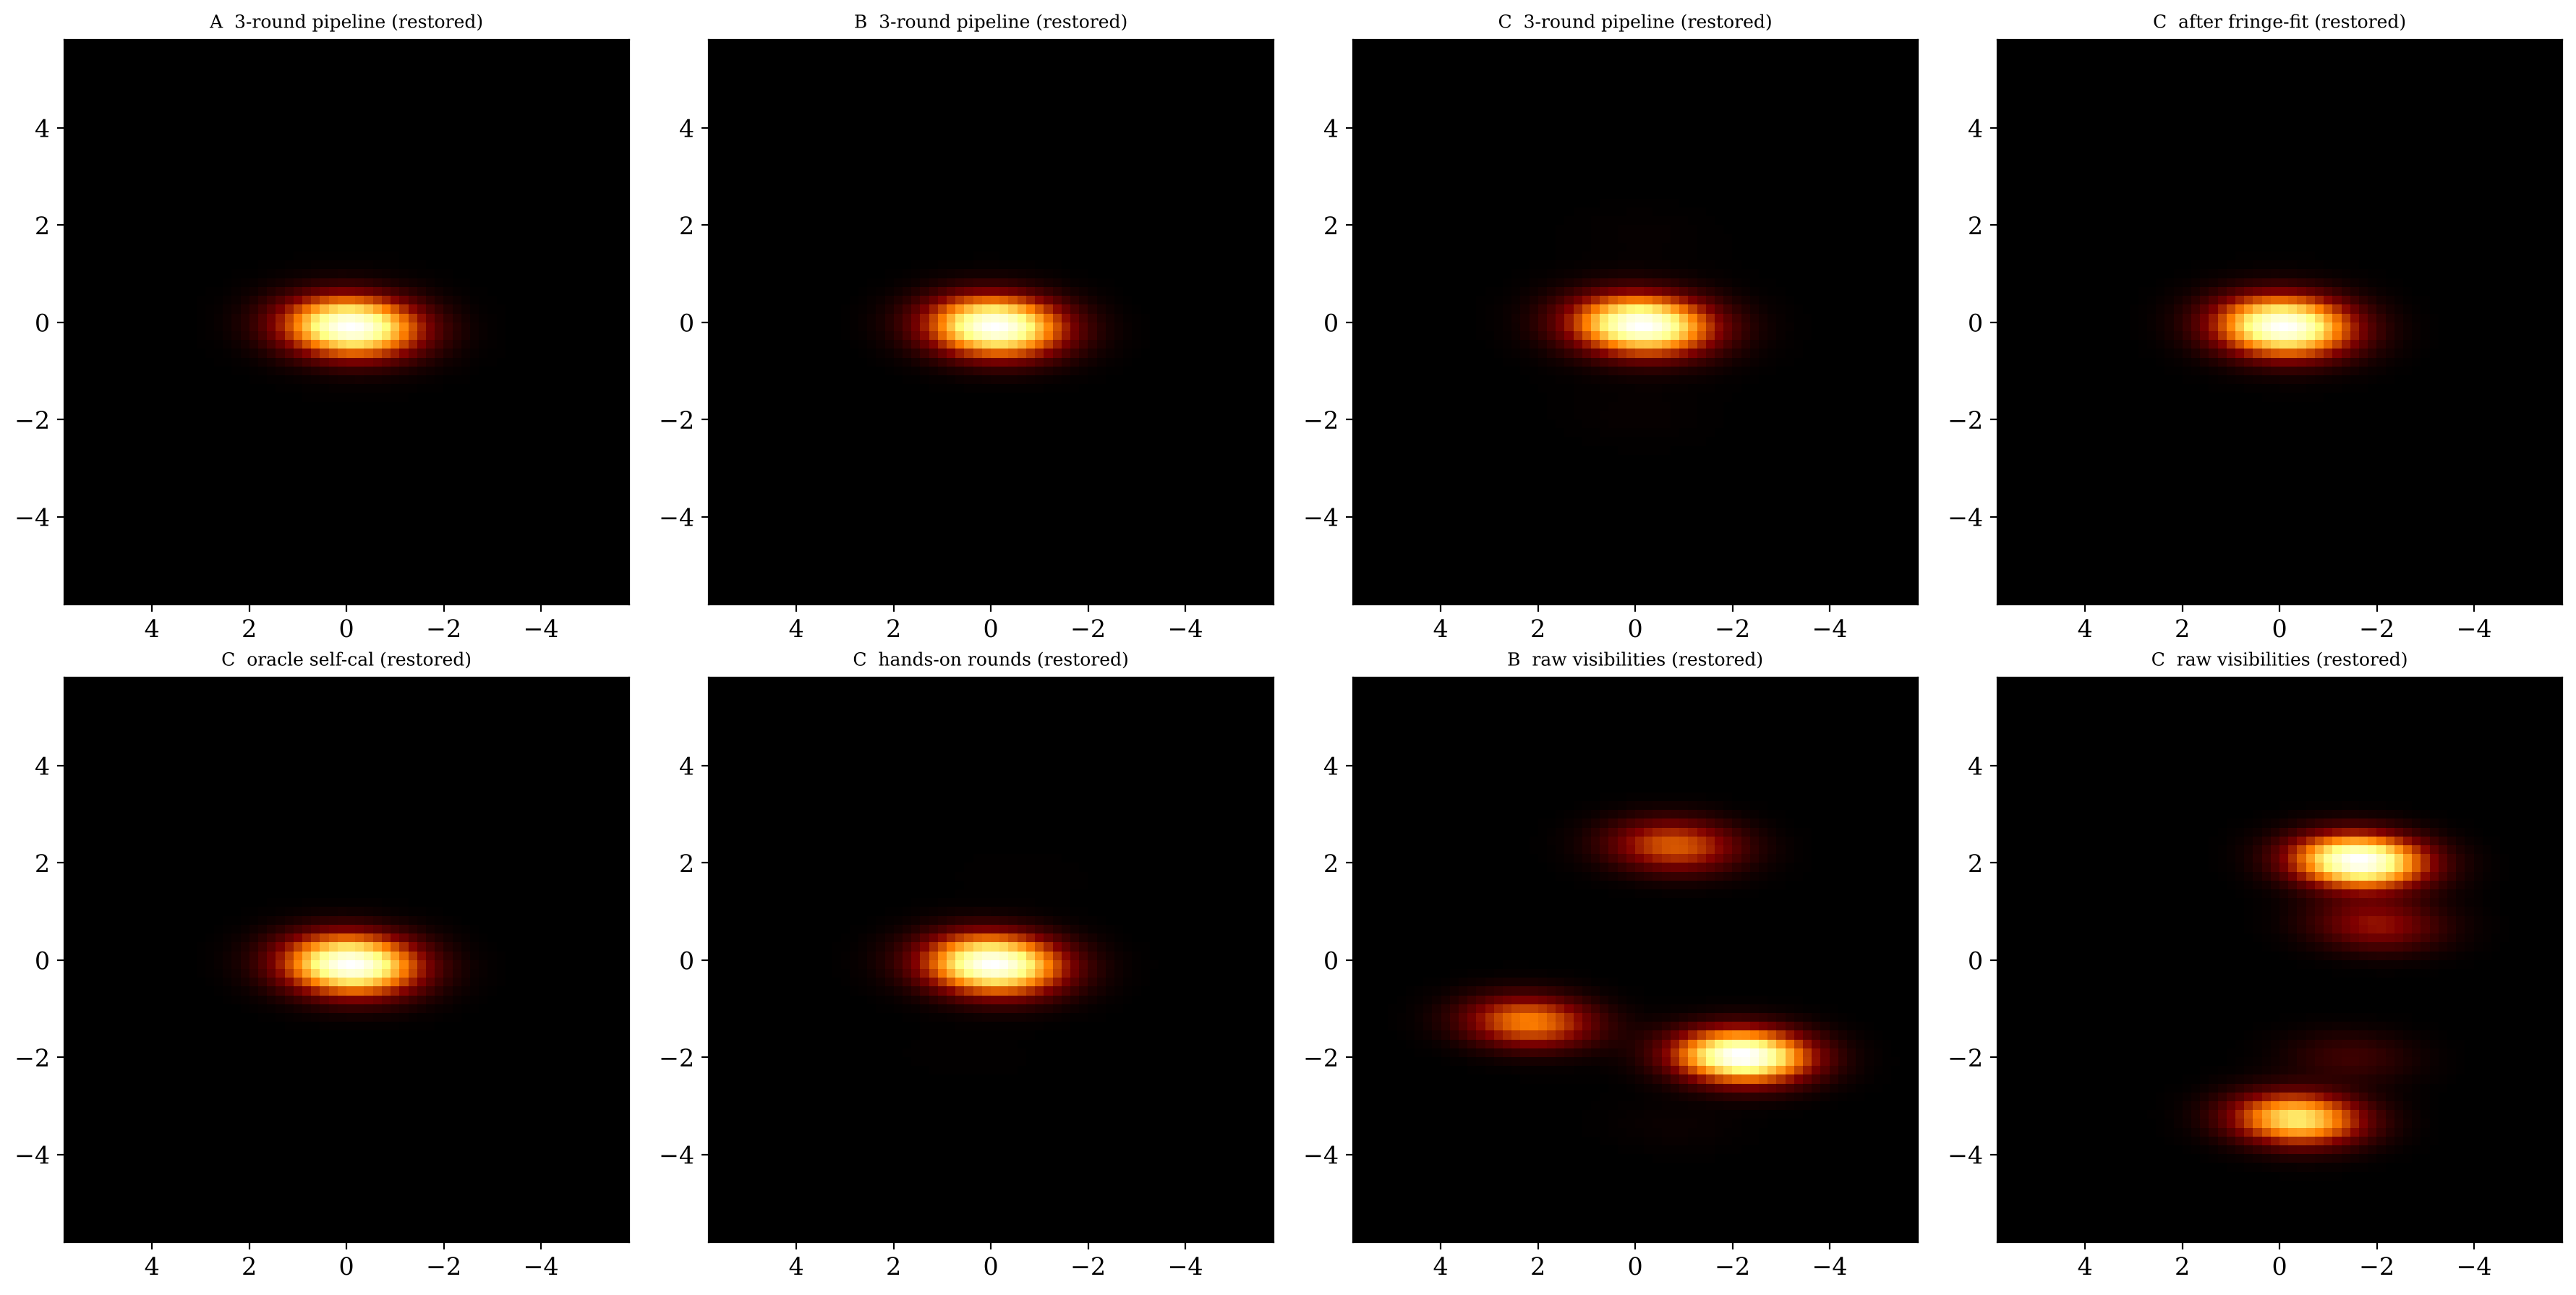

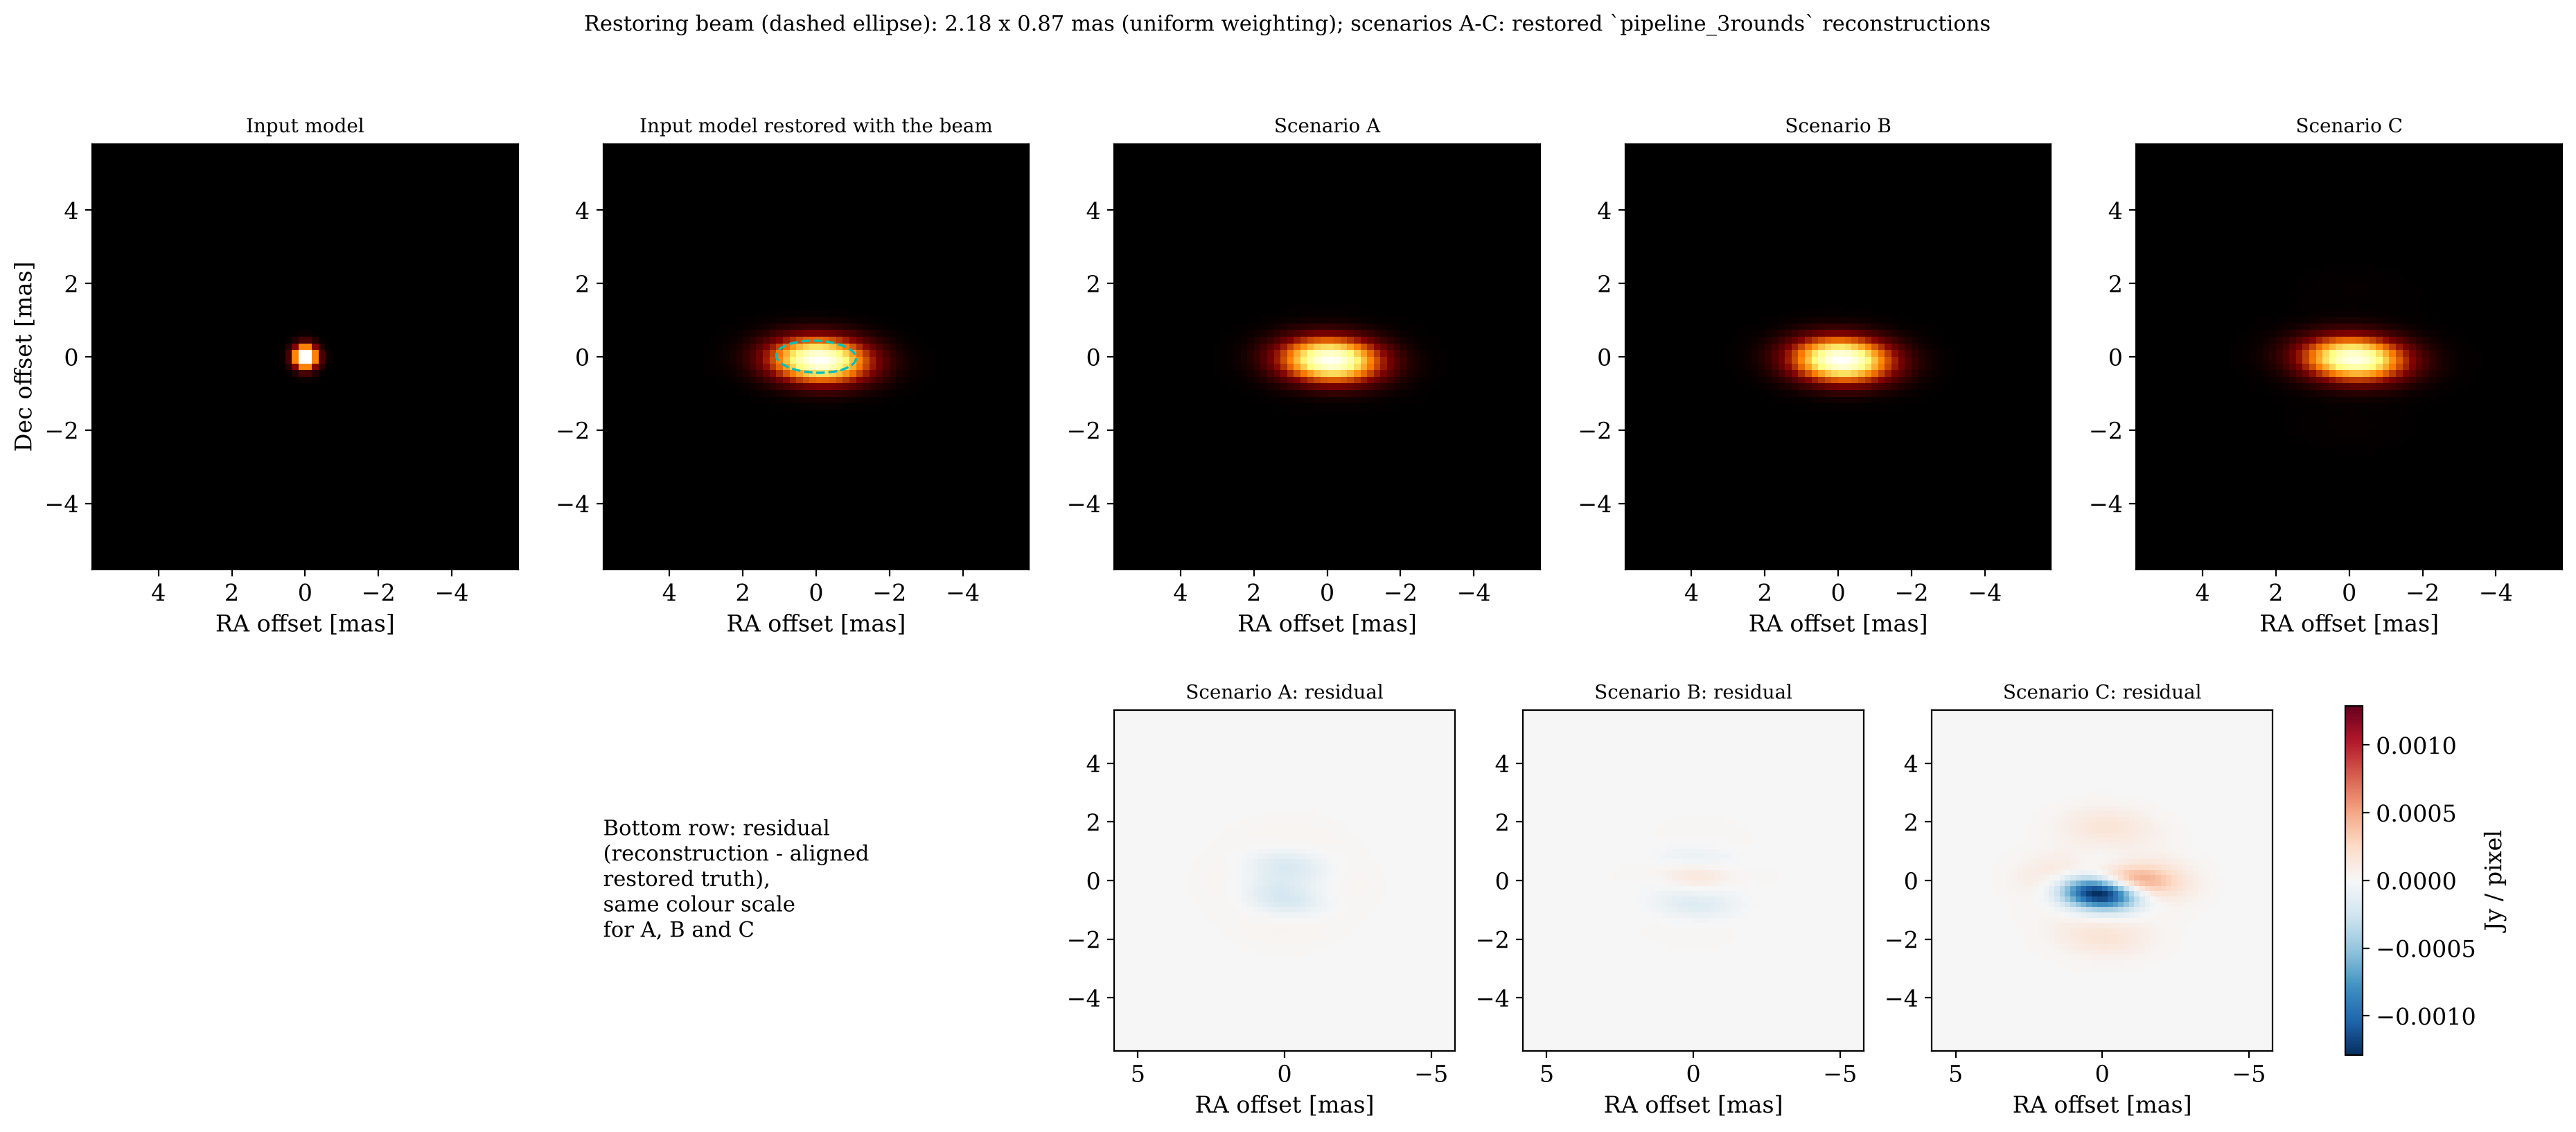

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3))
for i, s in enumerate(scr['sites']):
    ax[0].plot(scr['t'], scr['tau_ns'][i] - scr['tau_ns'][i].mean(), lw=1)
ax[0].set(title='Scenario C: simulated delay (mean removed)', xlabel='time [UTC h]', ylabel='delay [ns]')
for i, s in enumerate(scr['sites']):
    ax[1].plot(scr['t'], scr['dtec'][i], lw=1)
ax[1].set(title='Scenario C: simulated dTEC', xlabel='time [UTC h]', ylabel='dTEC [TECU]')
for name, o, c in (('B', obs_B, 'tab:red'), ('C', obs_C, 'tab:purple'), ('A', obs_A, 'tab:green')):
    ax[2].plot(np.hypot(o.data['u'], o.data['v'])/1e6, np.abs(o.data['vis']), '.', ms=2, alpha=.4, color=c, label=name)
ax[2].plot(uv_ideal/1e6, np.abs(obs_ideal.data['vis']), '.', ms=1, color='k', label='reference')
ax[2].set(title='Visibility amplitude (raw data)', xlabel=r'uv [M$\lambda$]', ylabel='Jy'); ax[2].legend(markerscale=4)
for name, o, c in (('B oracle self-cal', cal_B_oracle, 'tab:red'), ('C oracle self-cal', cal_C_oracle, 'tab:purple')):
    ax[3].plot(np.hypot(o.data['u'], o.data['v'])/1e6, np.abs(o.data['vis']), '.', ms=2, alpha=.4, color=c, label=name)
ax[3].plot(uv_ideal/1e6, np.abs(obs_ideal.data['vis']), '.', ms=1, color='k', label='reference')
ax[3].set(title='After oracle self-cal', xlabel=r'uv [M$\lambda$]', ylabel='Jy'); ax[3].legend(markerscale=4)
plt.tight_layout(); save_fig(fig, '03_diagnostics_screen_and_visibilities'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(-15, 15, 121); xg = np.linspace(-15, 15, 400)
for name, c in (('A', 'tab:green'), ('B', 'tab:red'), ('C', 'tab:purple')):
    r, sg = cp_resid[name]
    ax[0].hist(np.clip(r/sg, -15, 15), bins=bins, histtype='step', lw=1.8, density=True, color=c,
               label=f"{name}: rms {np.sqrt(np.mean(r**2)):.2f} deg = {np.sqrt(np.mean((r/sg)**2)):.2f} sigma")
ax[0].plot(xg, np.exp(-xg**2/2)/np.sqrt(2*np.pi), 'k:', lw=1, label='thermal noise only: N(0, 1)')
ax[0].set(title='Closure-phase residuals w.r.t. the noise-free reference', xlabel='residual / sigma (clipped at 15)',
          ylabel='density', yscale='log', ylim=(1e-4, 1)); ax[0].legend(fontsize=8)
ax[1].hist(np.abs(G), bins=40, color='tab:purple', alpha=.7)
ax[1].set(title=r'Scenario C: decorrelation factor $|\Gamma_{ij}|$ per visibility', xlabel=r'$|\Gamma_{ij}|$', ylabel='number')
plt.tight_layout(); save_fig(fig, '04_closure_phase_residuals_and_decorrelation'); plt.show()

keys = list(recs)
fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for a, k in zip(ax.ravel(), keys):
    im = recs[k]; h = fov/2/mas
    a.imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot', extent=[h, -h, -h, h]); a.set_title(f'{k} (restored)', fontsize=9)
for a in ax.ravel()[len(keys):]: a.axis('off')
plt.tight_layout(); save_fig(fig, '05_reconstructions_all'); plt.show()

fig, ax = plt.subplots(2, 5, figsize=(23, 9))
h = fov/2/mas
panels = [('Input model', im_src.regrid_image(fov, npix)), ('Input model restored with the beam', truth_g),
          ('Scenario A', recs['A  3-round pipeline']), ('Scenario B', recs['B  3-round pipeline']),
          ('Scenario C', recs['C  3-round pipeline'])]
vmax = max(p[1].imvec.max() for p in panels[1:])
for k, (a, (t, im)) in enumerate(zip(ax[0], panels)):
    a.imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot', extent=[h, -h, -h, h], vmin=0, vmax=None if k == 0 else vmax)
    a.set_title(t, fontsize=10); a.set_xlabel('RA offset [mas]')
ax[0, 0].set_ylabel('Dec offset [mas]')
from matplotlib.patches import Ellipse
ax[0, 1].add_patch(Ellipse((0, 0), beam_params[1]/mas, beam_params[0]/mas, angle=-np.degrees(beam_params[2]),
                           fc='none', ec='c', lw=1.2, ls='--'))     # restoring beam FWHM, drawn at the centre
ax[1, 0].axis('off'); ax[1, 1].axis('off')
ax[1, 1].text(0.0, 0.5, 'Bottom row: residual\n(reconstruction - aligned\nrestored truth),\nsame colour scale\nfor A, B and C', fontsize=11, va='center')
rmax = max(np.abs(aligned[f'{s}  3-round pipeline'][0].imvec - aligned[f'{s}  3-round pipeline'][1].imvec).max() for s in 'ABC')
for a, s in zip(ax[1, 2:], 'ABC'):
    im1, im2 = aligned[f'{s}  3-round pipeline']; hh = im1.fovx()/2/mas
    r = a.imshow((im1.imvec - im2.imvec).reshape(im1.ydim, im1.xdim), cmap='RdBu_r', vmin=-rmax, vmax=rmax, extent=[hh, -hh, -hh, hh])
    a.set_title(f'Scenario {s}: residual', fontsize=10); a.set_xlabel('RA offset [mas]'); a.set_xlim(h, -h); a.set_ylim(-h, h)
plt.colorbar(r, ax=ax[1, 2:].tolist(), label='Jy / pixel', shrink=0.8)
fig.suptitle(f"Restoring beam (dashed ellipse): {beam_params[0]/mas:.2f} x {beam_params[1]/mas:.2f} mas ({beam_weighting} weighting); "
             "scenarios A-C: restored `pipeline_3rounds` reconstructions", fontsize=11)
save_fig(fig, '06_scenarios_A_B_C_vs_truth'); plt.show()

**Convergence of the data fit.** Evolution of the reduced $\chi^2$ of each data term over the iterations of `pipeline_3rounds`, for each scenario (iterations are cumulative over the three rounds; vertical lines mark the start of rounds 2 and 3, where the data are re-self-calibrated to the image reconstructed so far). A reduced $\chi^2$ of 1 (dotted line) means the model fits the data to within the thermal noise. The terms fitted change from round to round (round 1: closure phases and log closure amplitudes on the raw data; rounds 2 and 3: bispectrum and amplitudes on the self-calibrated data), so a curve is only drawn in the rounds where its term is active, and values are not strictly comparable across rounds. A curve that settles near 1 means the data can be fitted to within the noise; a curve that plateaus well above 1 means that no image, combined with antenna-based calibration, can explain the data, which is what non-antenna-based errors such as the in-band decorrelation of scenario C produce.

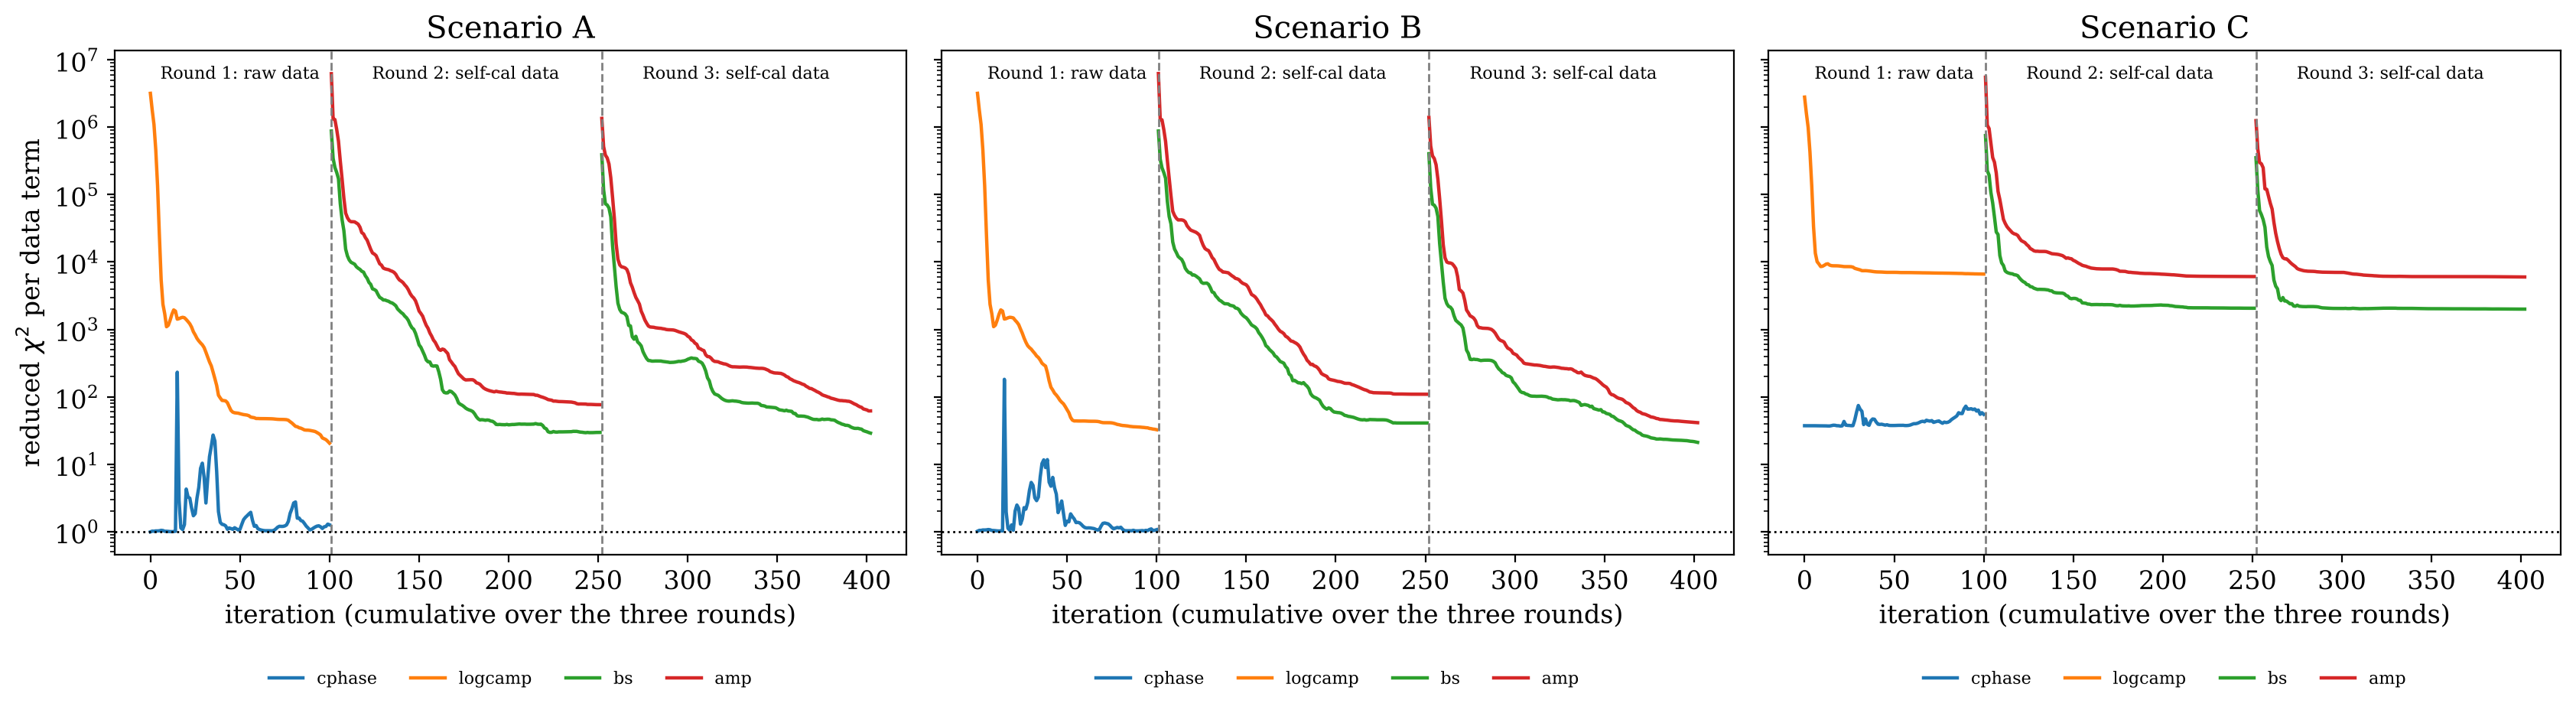

scenario  round   final reduced chi2 per data term
       A      1   cphase = 1.26  logcamp = 20.53
       A      2   bs = 29.70  amp = 76.52
       A      3   bs = 28.99  amp = 61.88
       B      1   cphase = 1.07  logcamp = 32.58
       B      2   bs = 40.94  amp = 109.32
       B      3   bs = 21.12  amp = 41.40
       C      1   cphase = 55.10  logcamp = 6626.51
       C      2   bs = 2064.49  amp = 6085.57
       C      3   bs = 2002.34  amp = 6000.20


In [14]:
terms = ['cphase', 'logcamp', 'bs', 'amp']
colors = dict(zip(terms, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))
round_names = ['Round 1: raw data', 'Round 2: self-cal data', 'Round 3: self-cal data']

fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), sharey=True)
for a, sc_name in zip(ax, 'ABC'):
    h = hist_pipeline[sc_name]; offset = 0; edges = [0]; labelled = set()
    for r in sorted({x['round'] for x in h}):
        rec = [x for x in h if x['round'] == r]
        xs = np.array([offset + x['iter'] for x in rec])
        for t in terms:
            if t in rec[0]:
                a.semilogy(xs, [x[t] for x in rec], color=colors[t], lw=1.6, label=None if t in labelled else t)
                labelled.add(t)
        a.text((offset + xs.max())/2, 0.97, round_names[r], transform=a.get_xaxis_transform(), ha='center', va='top', fontsize=8)
        offset = xs.max() + 1; edges.append(offset)
    for e in edges[1:-1]: a.axvline(e, color='gray', ls='--', lw=1)
    a.axhline(1.0, color='k', ls=':', lw=1)
    a.set(title=f'Scenario {sc_name}', xlabel='iteration (cumulative over the three rounds)')
    a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8, frameon=False)
ax[0].set_ylabel(r'reduced $\chi^2$ per data term')
plt.tight_layout(); save_fig(fig, '07_chi2_convergence'); plt.show()

chi2_rows = []
print(f"{'scenario':>8s} {'round':>6s}   final reduced chi2 per data term")
for sc_name in 'ABC':
    h = hist_pipeline[sc_name]
    for r in sorted({x['round'] for x in h}):
        last = [x for x in h if x['round'] == r][-1]
        chi2_rows.append([sc_name, r+1] + [last.get(t, '') for t in terms])
        print(f"{sc_name:>8s} {r+1:>6d}   " + '  '.join(f"{t} = {last[t]:.2f}" for t in terms if t in last))

**Convergence of every reconstruction.** The same diagnostic for all the reconstructions of Section 8, including the references (oracle self-calibration, hands-on rounds on oracle-calibrated data, raw visibilities) and scenario C after the idealised fringe fit. Each panel has its own vertical scale. Note the raw-visibility runs: their $\chi^2$ against the corrupted visibilities stays orders of magnitude above 1, because no image can explain visibilities whose station phases are scrambled.

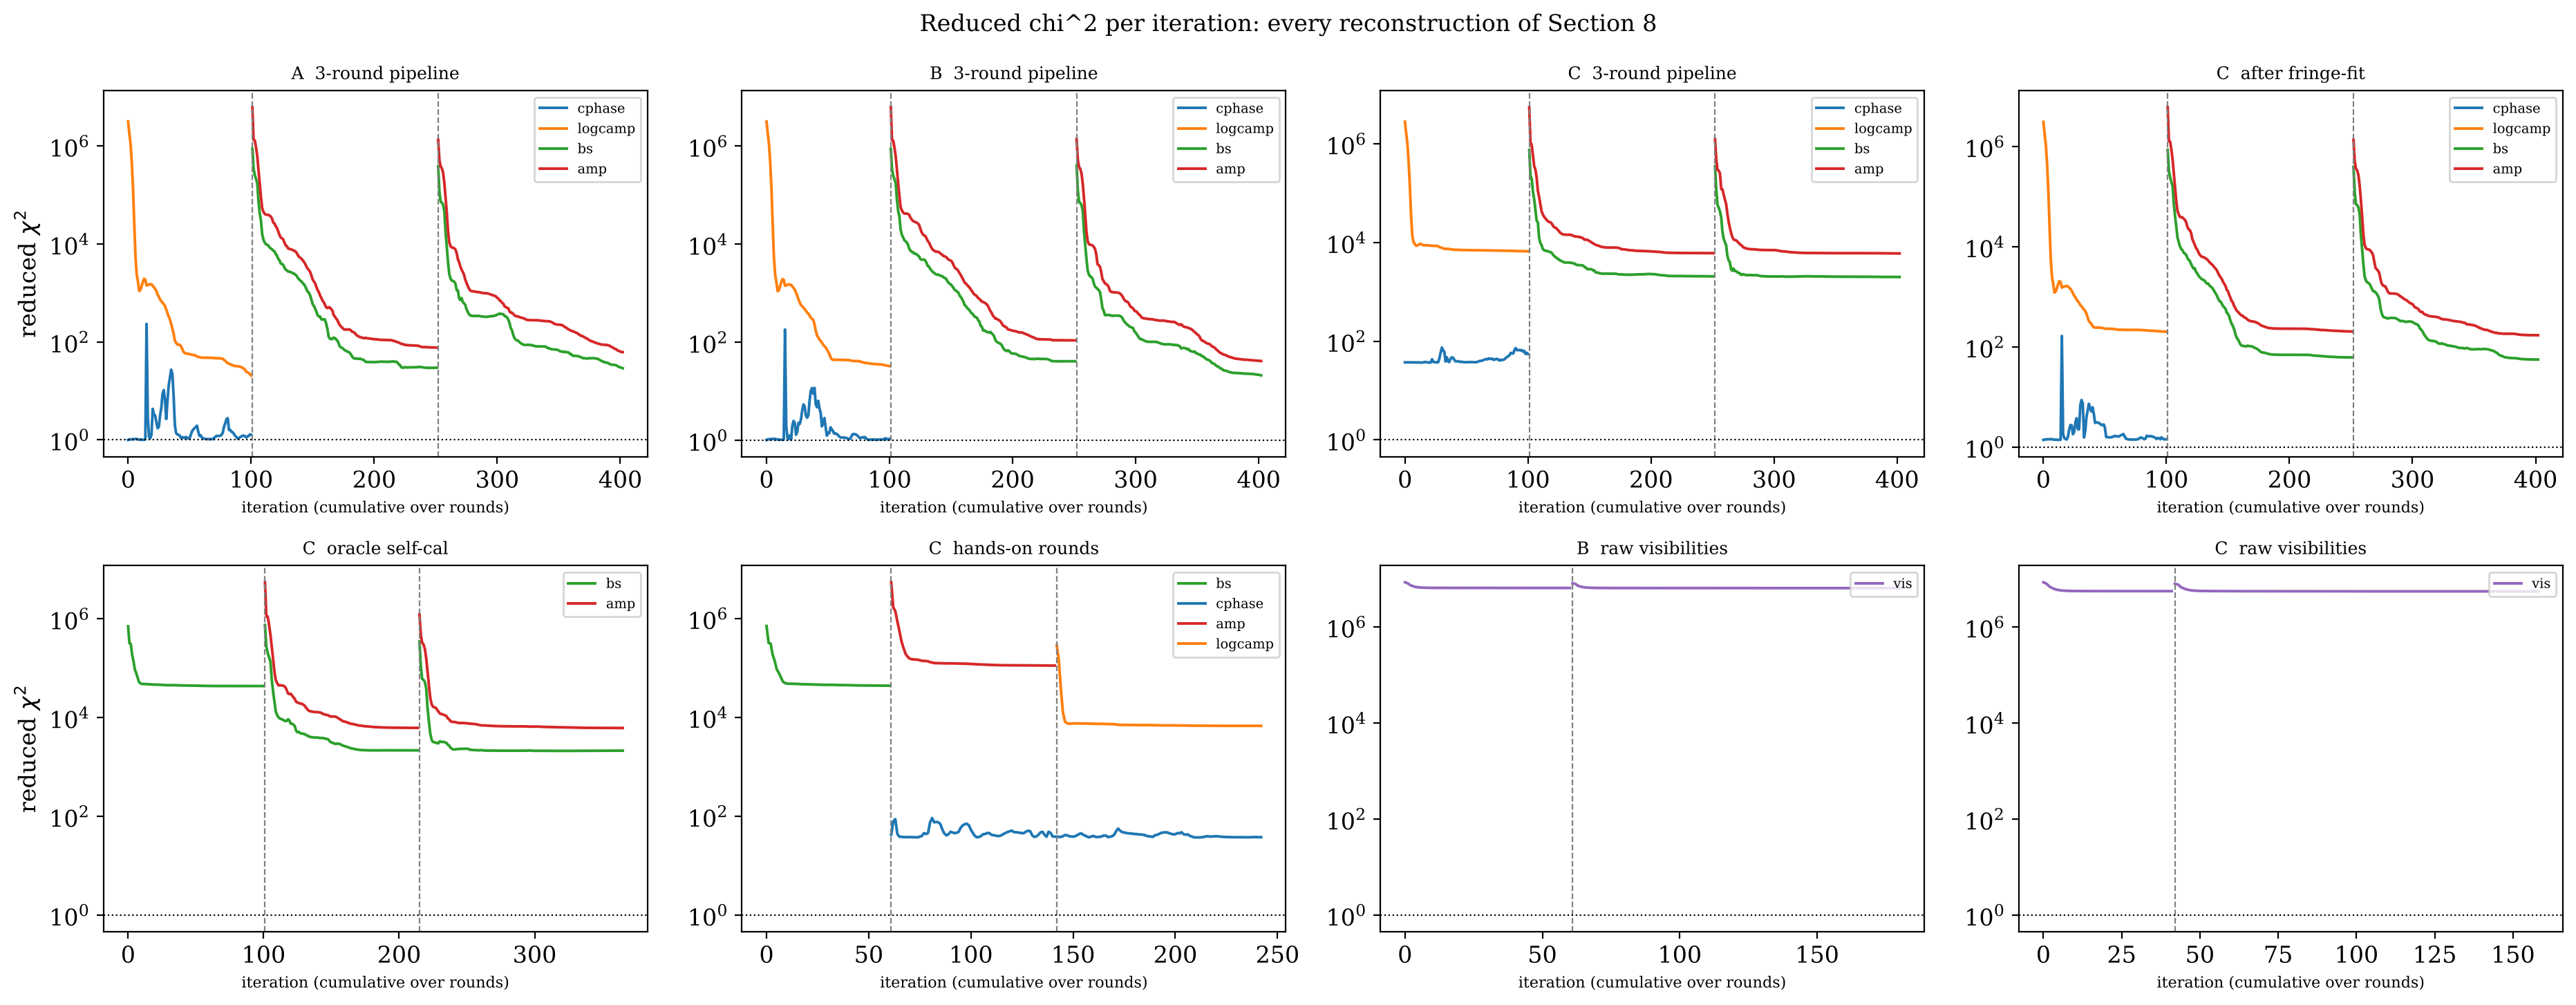

In [15]:
plot_chi2_histories(hist, '07b_chi2_convergence_all_reconstructions', 'Reduced chi^2 per iteration: every reconstruction of Section 8')

## 10. Comparison of imaging strategies

To place `pipeline_3rounds` between a calibration-free baseline and a best case, three strategies are compared on the same datasets (all with the same prior, final restoring beam and regularizer weights):

* **Closures only (no self-cal):** three rounds on `cphase` and `logcamp` only. It needs no calibration at all.
* **`pipeline_3rounds`:** the pipeline of Section 8, with iterative self-calibration to its own images (the images of Section 8 are reused, not recomputed).
* **Oracle self-cal (reference):** the same structure self-calibrating to the true model.

The difference between the pipeline and the oracle is the cost of not knowing the source; the difference with the closures-only baseline shows what the self-calibration steps add under each scenario. This cell runs 5 more reconstructions (~10 min).

pipeline                         |  nrmse A      B      C |  nxcorr A      B      C


Closures only (no self-cal)      |     0.12   0.13   0.14 |      0.99   0.99   0.99
pipeline_3rounds                 |     0.02   0.01   0.09 |      1.00   1.00   1.00


Oracle self-cal (reference)      |     0.01   0.02   0.01 |      1.00   1.00   1.00
(463 s)


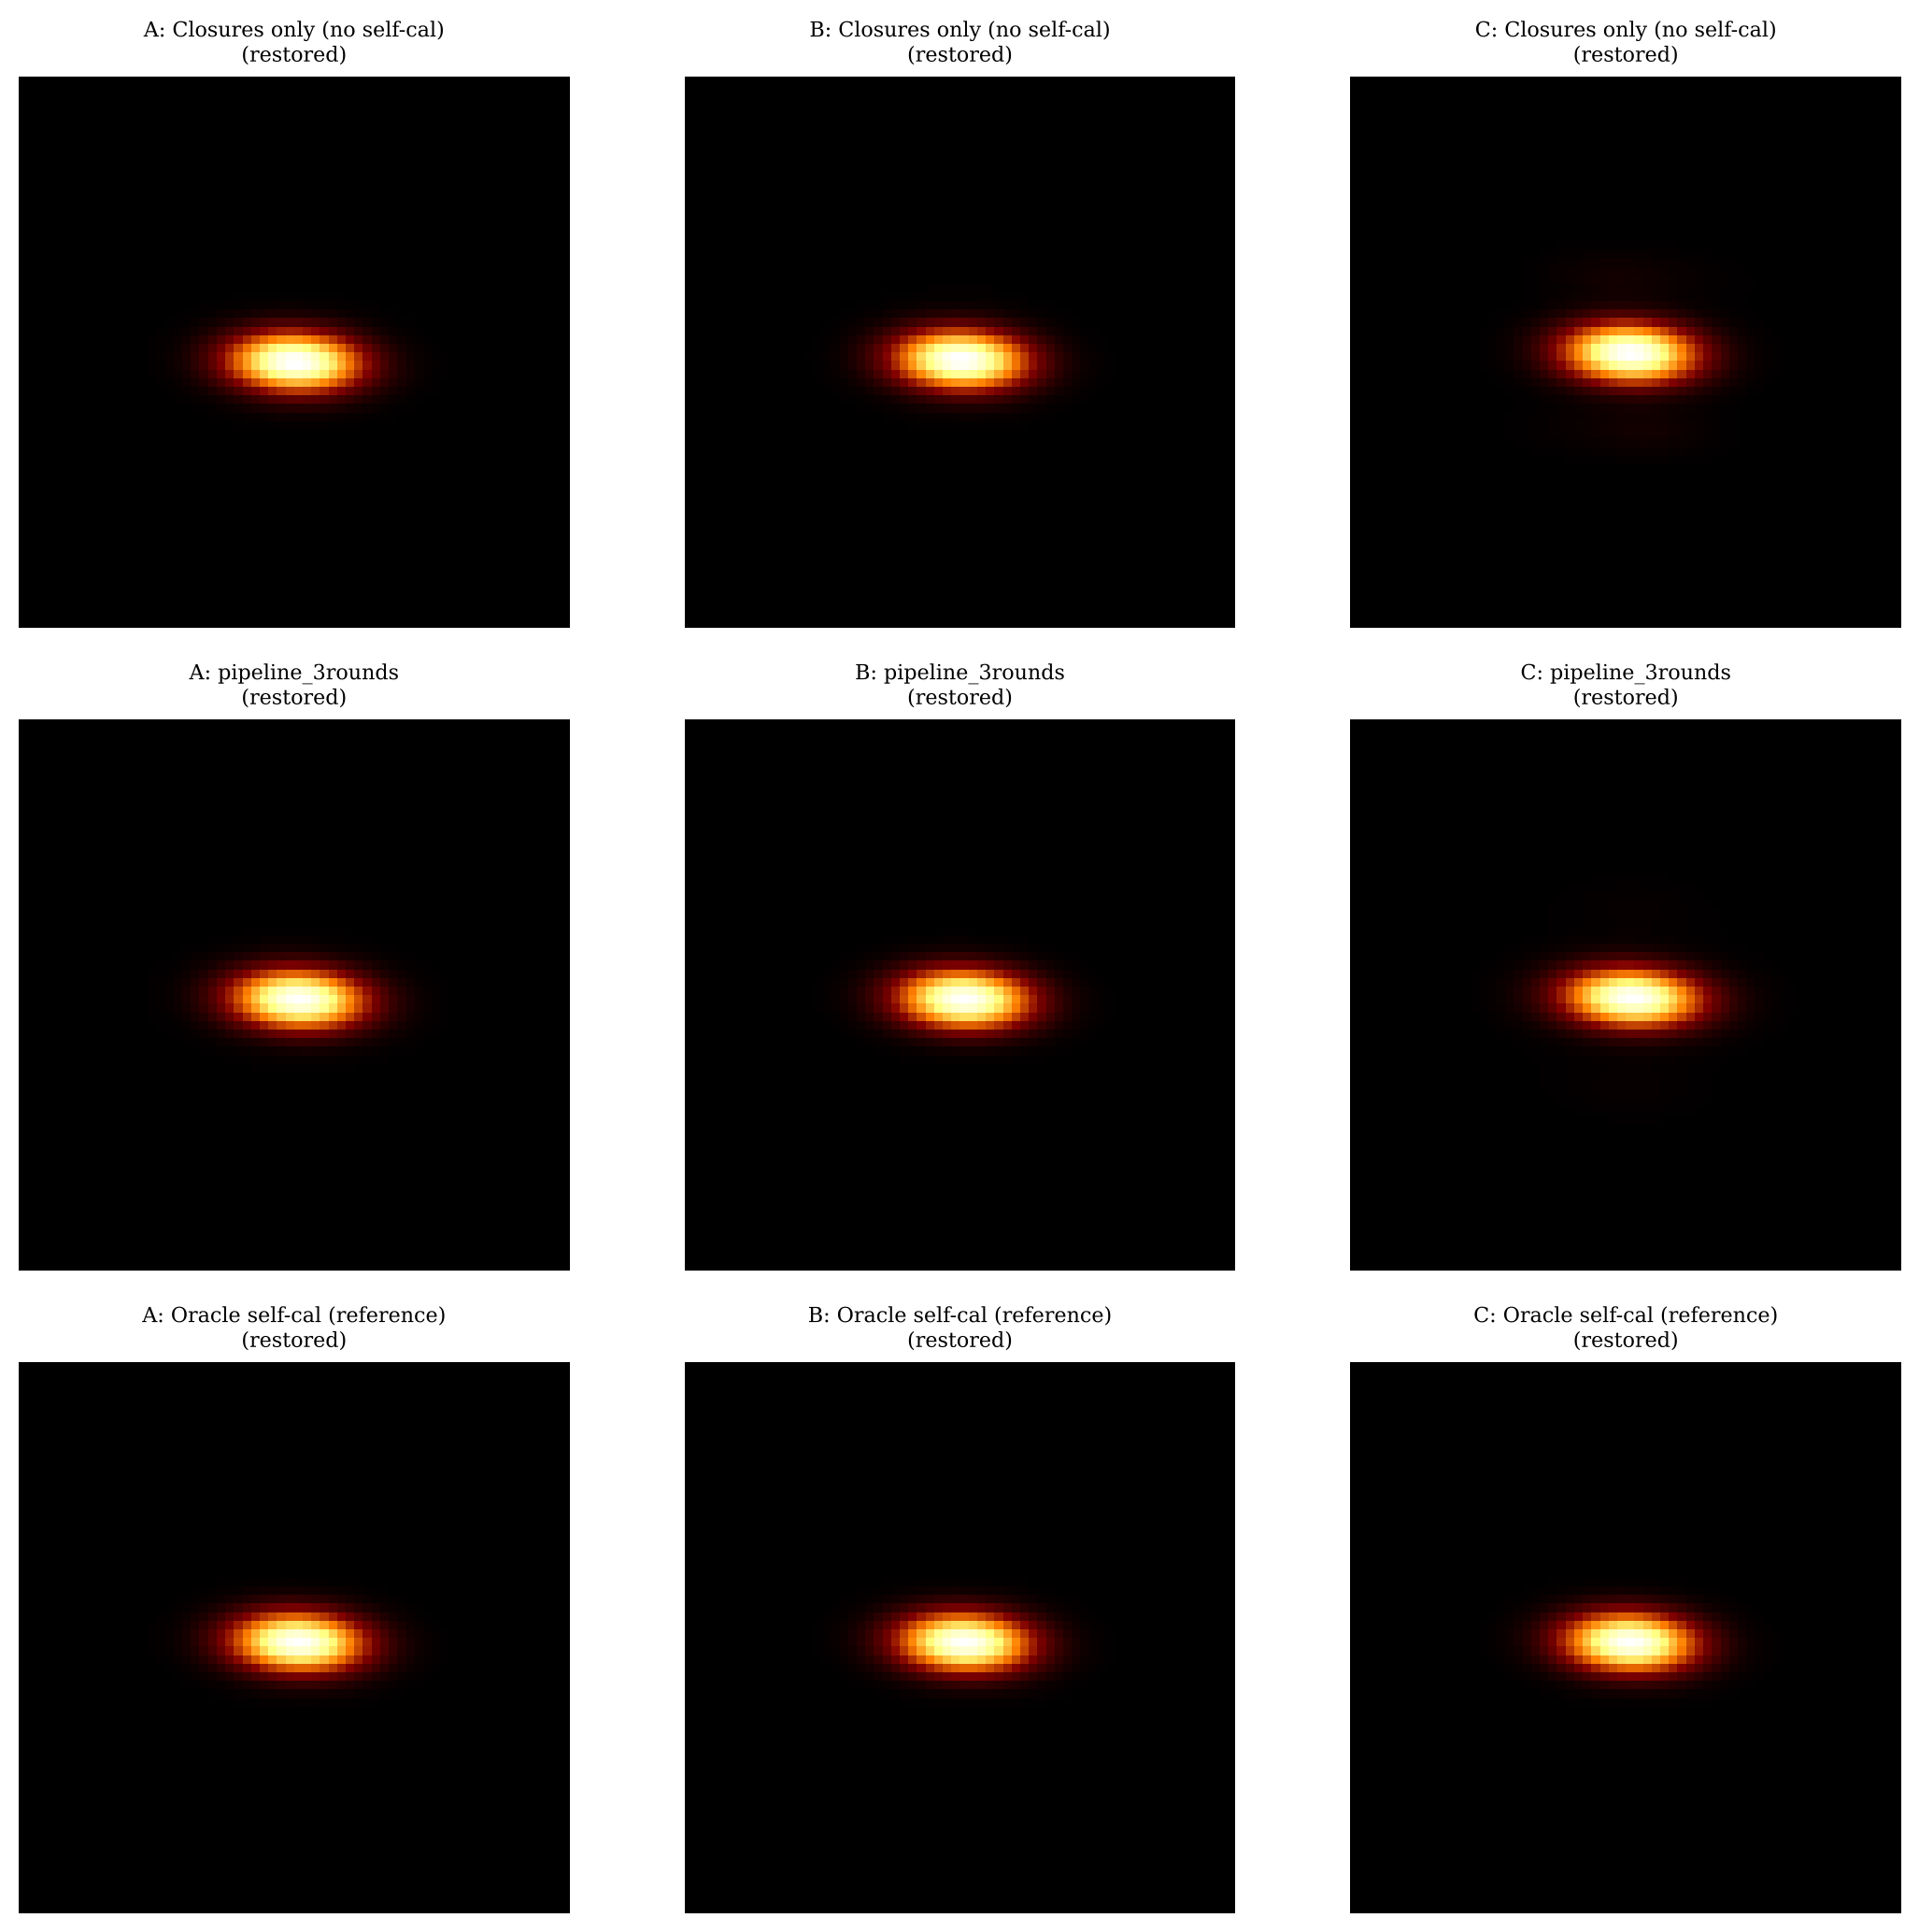

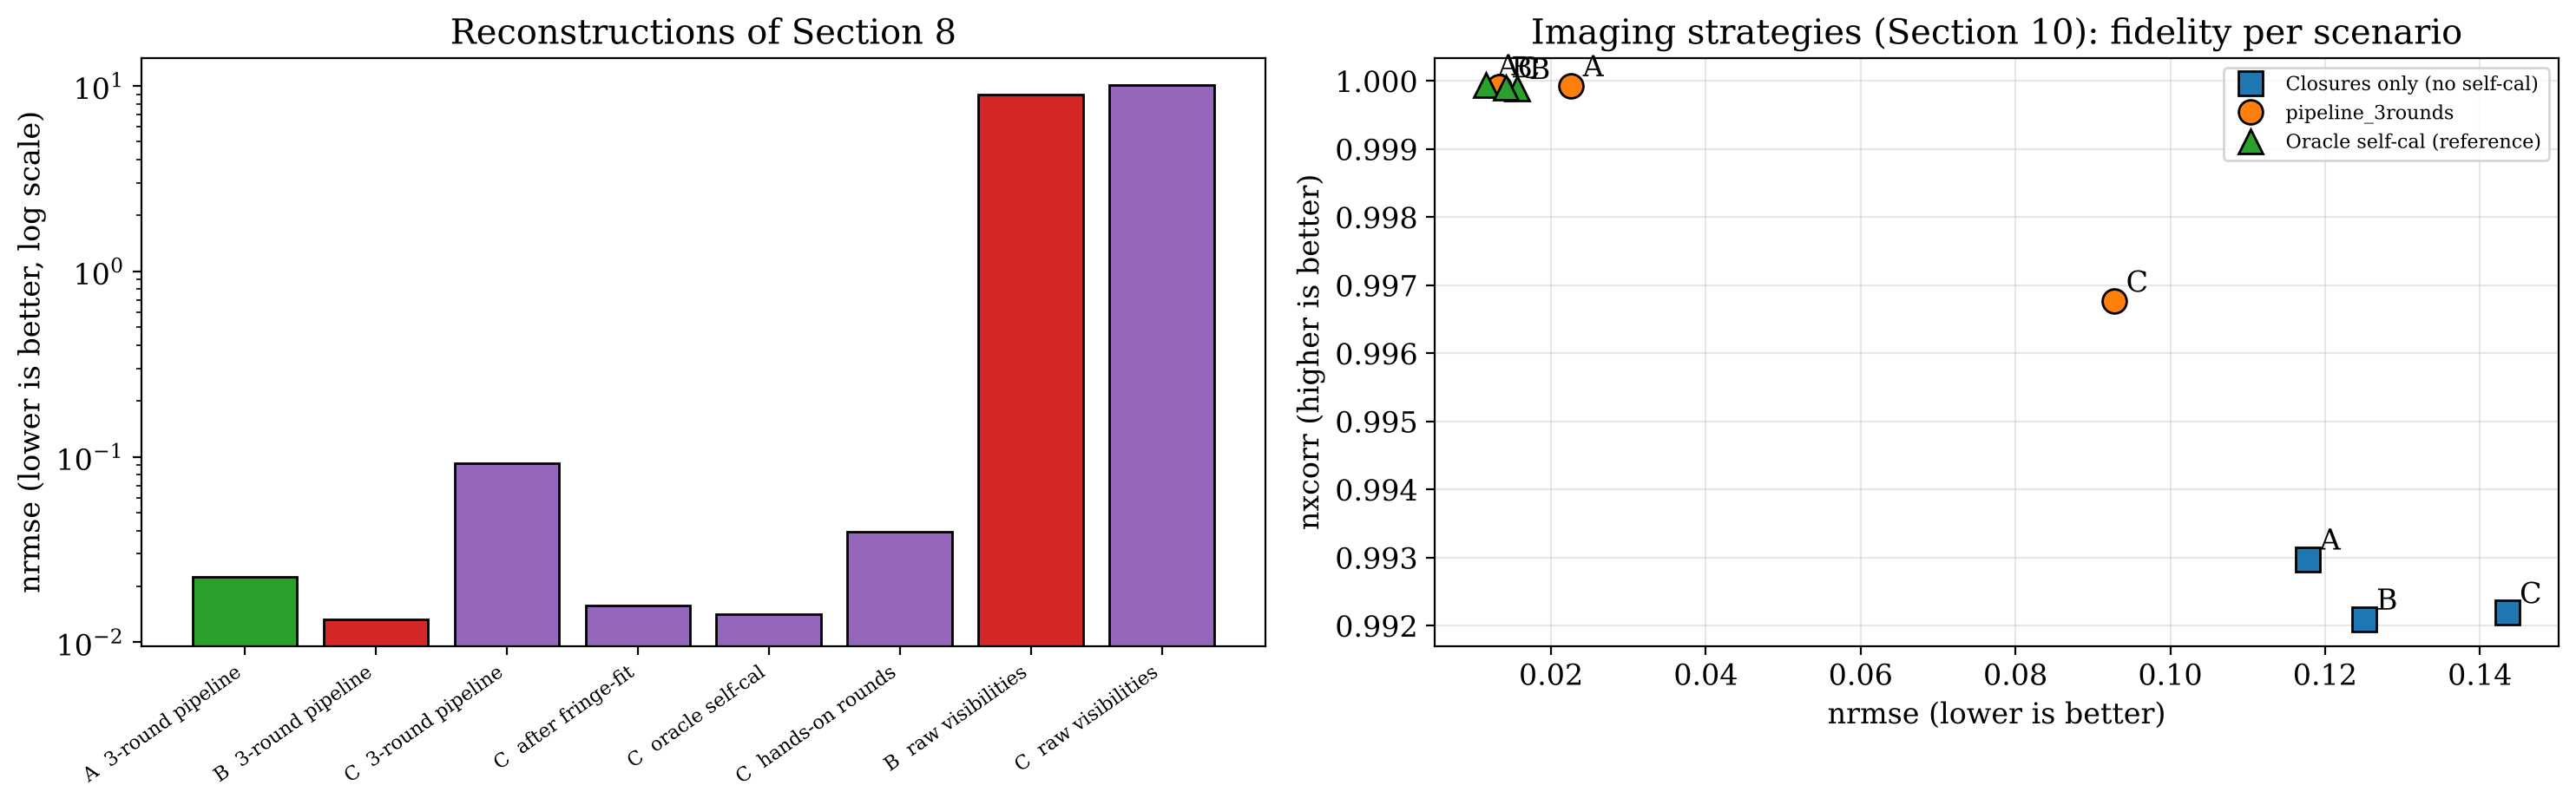

Total run time so far: 22.9 min


In [16]:
candidates = {
 'Closures only (no self-cal)': [
     {'data_term': CL, 'reg_term': {'simple': w_simple, **FM_CL}, 'maxit': i1},
     {'data_term': CL, 'reg_term': {'tv': w_tv, **FM_CL},      'maxit': i2, 'blur_frac': 1.0},
     {'data_term': CL, 'reg_term': {'tv': w_tv, **FM_CL},      'maxit': i3, 'blur_frac': 0.5}],
 'pipeline_3rounds':            pipeline_3rounds,
 'Oracle self-cal (reference)': pipeline_oracle,
}
datasets = {'A': obs_A, 'B': obs_B, 'C': obs_C}

study = {}; study_rows = []; study_hist = {}; t_st = time.time()
print(f"{'pipeline':32s} | {'nrmse A':>8s} {'B':>6s} {'C':>6s} | {'nxcorr A':>9s} {'B':>6s} {'C':>6s}")
for name, rounds in candidates.items():
    nr, xc = {}, {}
    for sc_name, o in datasets.items():
        if name == 'pipeline_3rounds':
            im = recs[f'{sc_name}  3-round pipeline']                      # already computed in Section 8
            study_hist[(name, sc_name)] = hist[f'{sc_name}  3-round pipeline']
        elif name.startswith('Oracle') and sc_name == 'C':
            im = recs['C  oracle self-cal']                                # already computed in Section 8
            study_hist[(name, sc_name)] = hist['C  oracle self-cal']
        else:
            study_hist[(name, sc_name)] = []
            im = run_pipeline(o, prior, zbl, rounds, model=im_src, final_beam=beam_params, history=study_hist[(name, sc_name)])
        study[(name, sc_name)] = im
        xc[sc_name], nr[sc_name] = fidelity(im)[:2]
        study_rows.append((name, sc_name, nr[sc_name], xc[sc_name], im.total_flux()))
    print(f"{name:32s} | {nr['A']:8.2f} {nr['B']:6.2f} {nr['C']:6.2f} | {xc['A']:9.2f} {xc['B']:6.2f} {xc['C']:6.2f}")
print(f"({time.time()-t_st:.0f} s)")

fig, ax = plt.subplots(len(candidates), 3, figsize=(11, 3.5*len(candidates)))
h = fov/2/mas
for r, name in enumerate(candidates):
    for c_, sc_name in enumerate('ABC'):
        im = study[(name, sc_name)]
        ax[r, c_].imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot', extent=[h, -h, -h, h]); ax[r, c_].axis('off')
        ax[r, c_].set_title(f'{sc_name}: {name}\n(restored)', fontsize=8)
plt.tight_layout(); save_fig(fig, '08_imaging_strategies_comparison'); plt.show()

# Summary figure: fidelity of every reconstruction of Sections 8 and 10
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
lab = [r[0] for r in metrics_rows]; x = np.arange(len(lab))
cols = ['tab:green' if l.startswith('A') else 'tab:red' if l.startswith('B') else 'tab:purple' for l in lab]
ax[0].bar(x, [r[5] for r in metrics_rows], color=cols, edgecolor='k'); ax[0].set_ylabel('nrmse (lower is better, log scale)'); ax[0].set_yscale('log')
ax[0].set_xticks(x); ax[0].set_xticklabels(lab, rotation=35, ha='right', fontsize=8); ax[0].set_title('Reconstructions of Section 8')
for name, mk in zip(candidates, ['s', 'o', '^']):
    pts = [(r[2], r[3]) for r in study_rows if r[0] == name]
    ax[1].plot([p[0] for p in pts], [p[1] for p in pts], mk, ms=10, ls='none', label=name, mec='k')
    for (nr_, xc_), s in zip(pts, 'ABC'): ax[1].annotate(s, (nr_, xc_), xytext=(5, 4), textcoords='offset points')
ax[1].set(xlabel='nrmse (lower is better)', ylabel='nxcorr (higher is better)', title='Imaging strategies (Section 10): fidelity per scenario')
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); save_fig(fig, '09_fidelity_summary'); plt.show()
print(f"Total run time so far: {(time.time()-T0)/60:.1f} min")

**Convergence of the imaging strategies.** Reduced $\chi^2$ per iteration for every strategy and scenario of the comparison above. For `pipeline_3rounds` and for the oracle on scenario C the histories of Section 8 are shown (those reconstructions were reused, not recomputed).

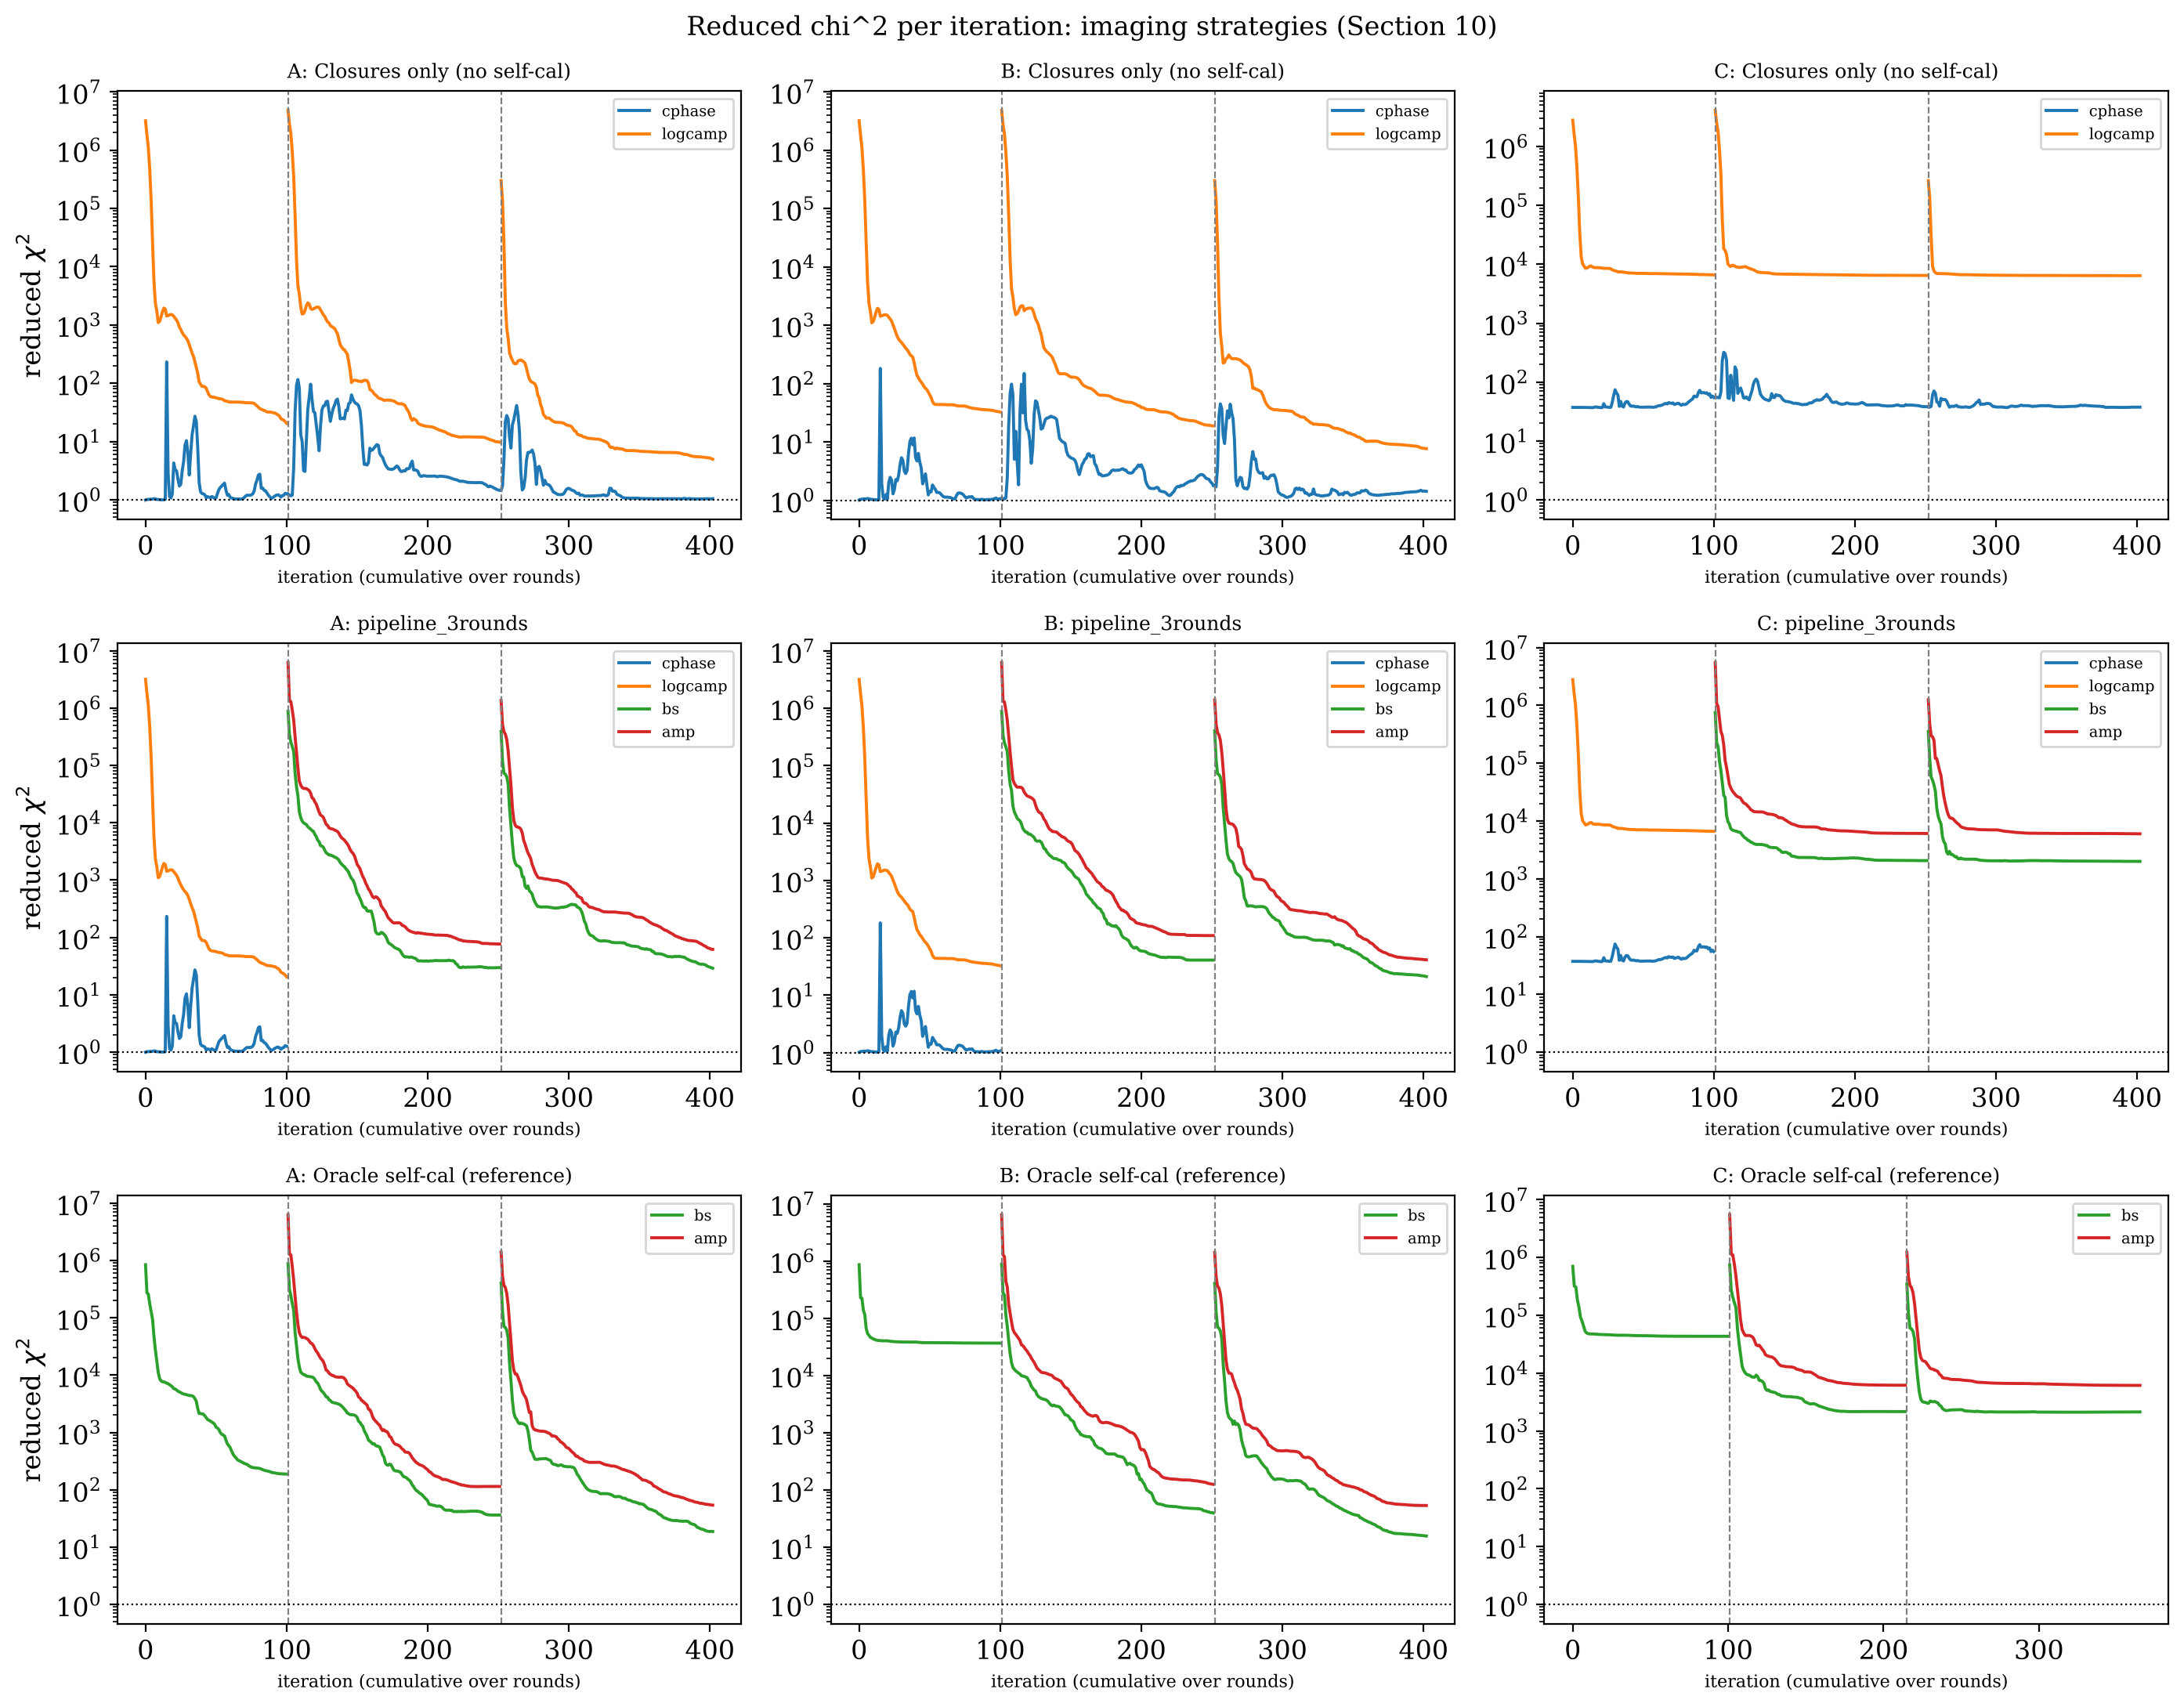

In [17]:
plot_chi2_histories({k: study_hist[k] for k in study}, '09b_chi2_convergence_imaging_strategies',
                    'Reduced chi^2 per iteration: imaging strategies (Section 10)', ncols=3)

## 11. Self-calibration to the final images: how well do the closures work?

This added case asks a practical question: **if the images obtained above are used as self-calibration models, how good are the calibrated visibilities?** A closure-based image that is right up to the resolution of the array should calibrate the data almost as well as the true source does.

For each scenario, the **raw** data are self-calibrated (amplitude and phase, one gain per station and scan, `self_cal(..., method='both', scan_solutions=True)`) to two models:

1. the **closures-only image** of Section 10 (`cphase` + `logcamp` only, no calibration at any stage): a direct test of what the closure quantities alone recover;
2. the **final image of `pipeline_3rounds`** (Section 8): the last image produced by the pipeline (closures first, then iterative self-calibration).

The models are the *unrestored* images (as in any self-calibration loop). Closure quantities do not fix the absolute position of the source, and a shift of the model is a pure antenna-based phase gradient that self-calibration would transfer to the data, so each model is first shifted (sub-pixel) to the position of the true source. This only removes the unknown absolute position; it does not change anything the closures measured.

The calibrated visibilities are then compared, baseline by baseline, with the **noise-free visibilities of the true source** (the reference observation of Section 3, same schedule):

* **reduced χ² against the truth**, $\langle |V_\mathrm{cal}-V_\mathrm{true}|^2/\sigma^2\rangle/2$: ≈ 1 means the calibrated data differ from the true visibilities only by thermal noise;
* **median amplitude error** [%] and **median phase error** [deg] on the baselines with SNR > 5.

The same numbers are given for the raw data (no calibration) and for the **oracle** calibration (self-calibration to the true model, Section 7; for scenario A, which has no gain errors, the oracle is the data themselves). Finally, each set of calibrated visibilities is **imaged** with the raw-visibility recipe of Section 8 (`vis_rounds`, starting from the same prior), recording the χ² of every iteration, and the images are scored with the same metrics. All of this is done with the **EVN + AVN + SKA-Mid** array. This cell runs 6 self-calibrations and 6 reconstructions.

  scenario A done (110 s)


  scenario B done (220 s)


  scenario C done (331 s)

sc.  visibilities                                model shift  chi2 vs truth  amp err [%]  phase err [deg]
A    raw data (no calibration)                                         1.00         0.07             0.04
A    self-cal to closures-only image               0.135 mas     8441653.12        37.56             2.37
A    self-cal to pipeline_3rounds image            0.022 mas       57046.91         4.58             1.03
A    oracle (A: data already calibrated)                               1.00         0.07             0.04
B    raw data (no calibration)                                  11980323.25         8.78            91.26
B    self-cal to closures-only image               0.091 mas    18919649.80        58.72             3.48
B    self-cal to pipeline_3rounds image            0.005 mas        2098.95         1.03             0.28
B    oracle (true model)                                               0.91         0.07             0.04
C    raw data (no c

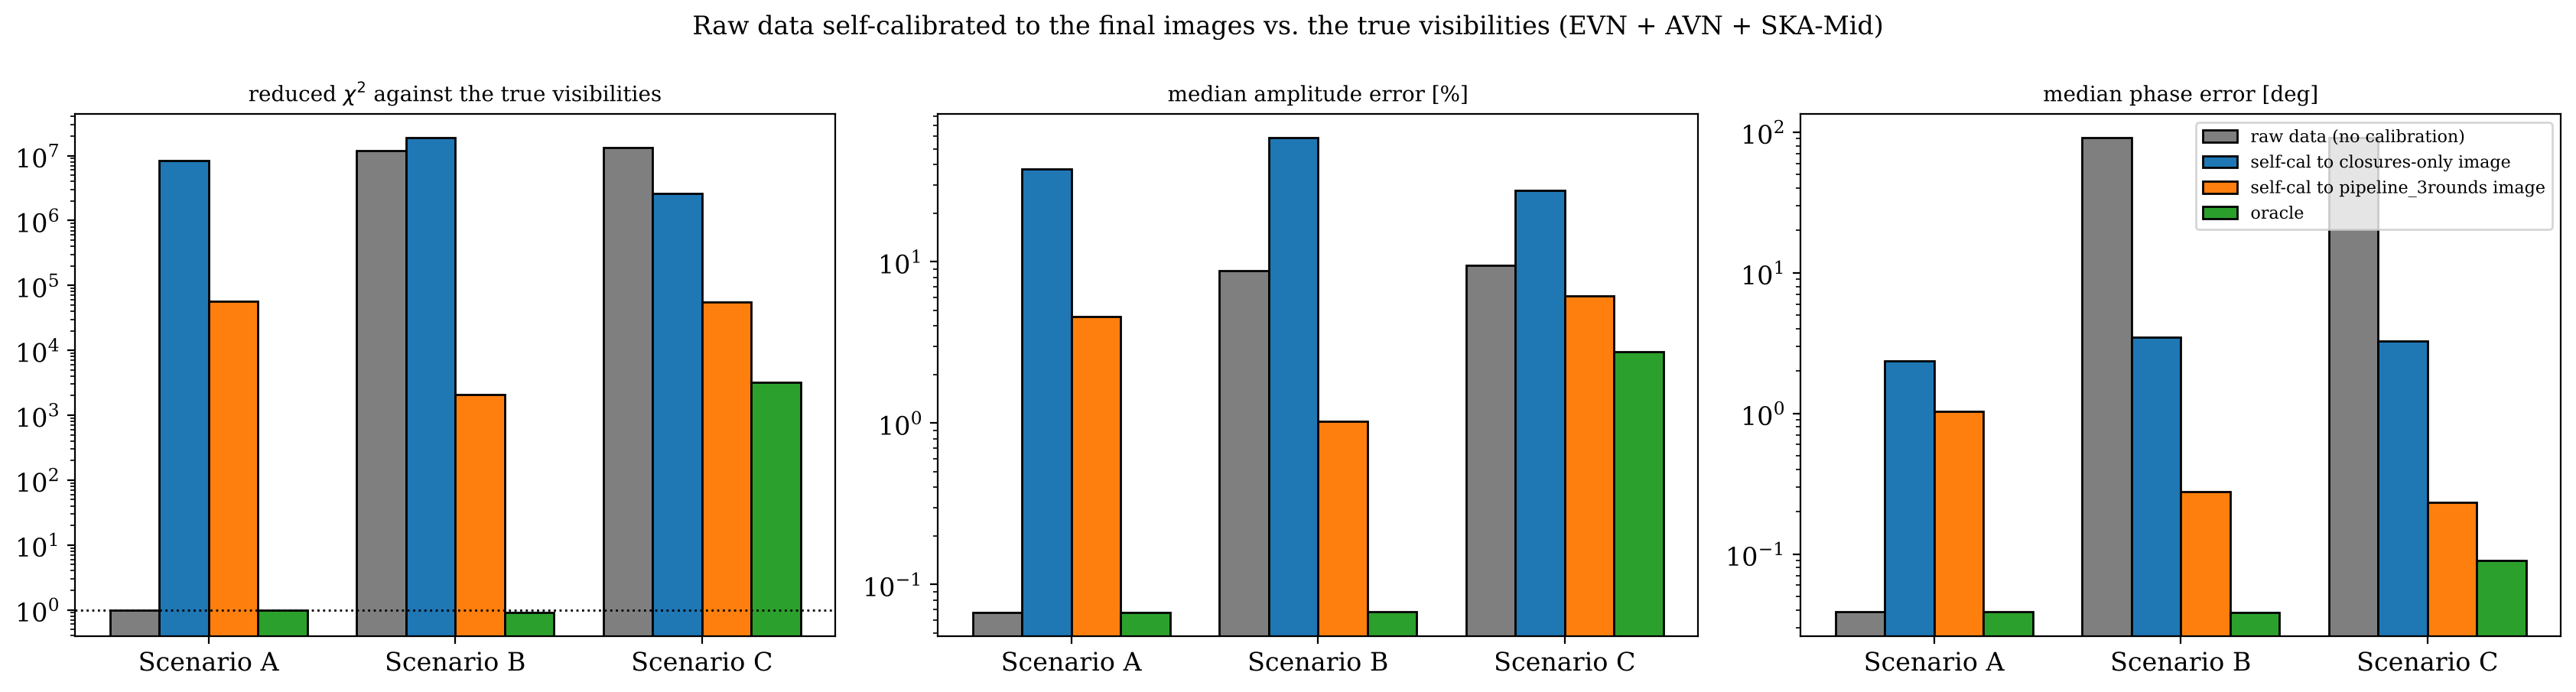

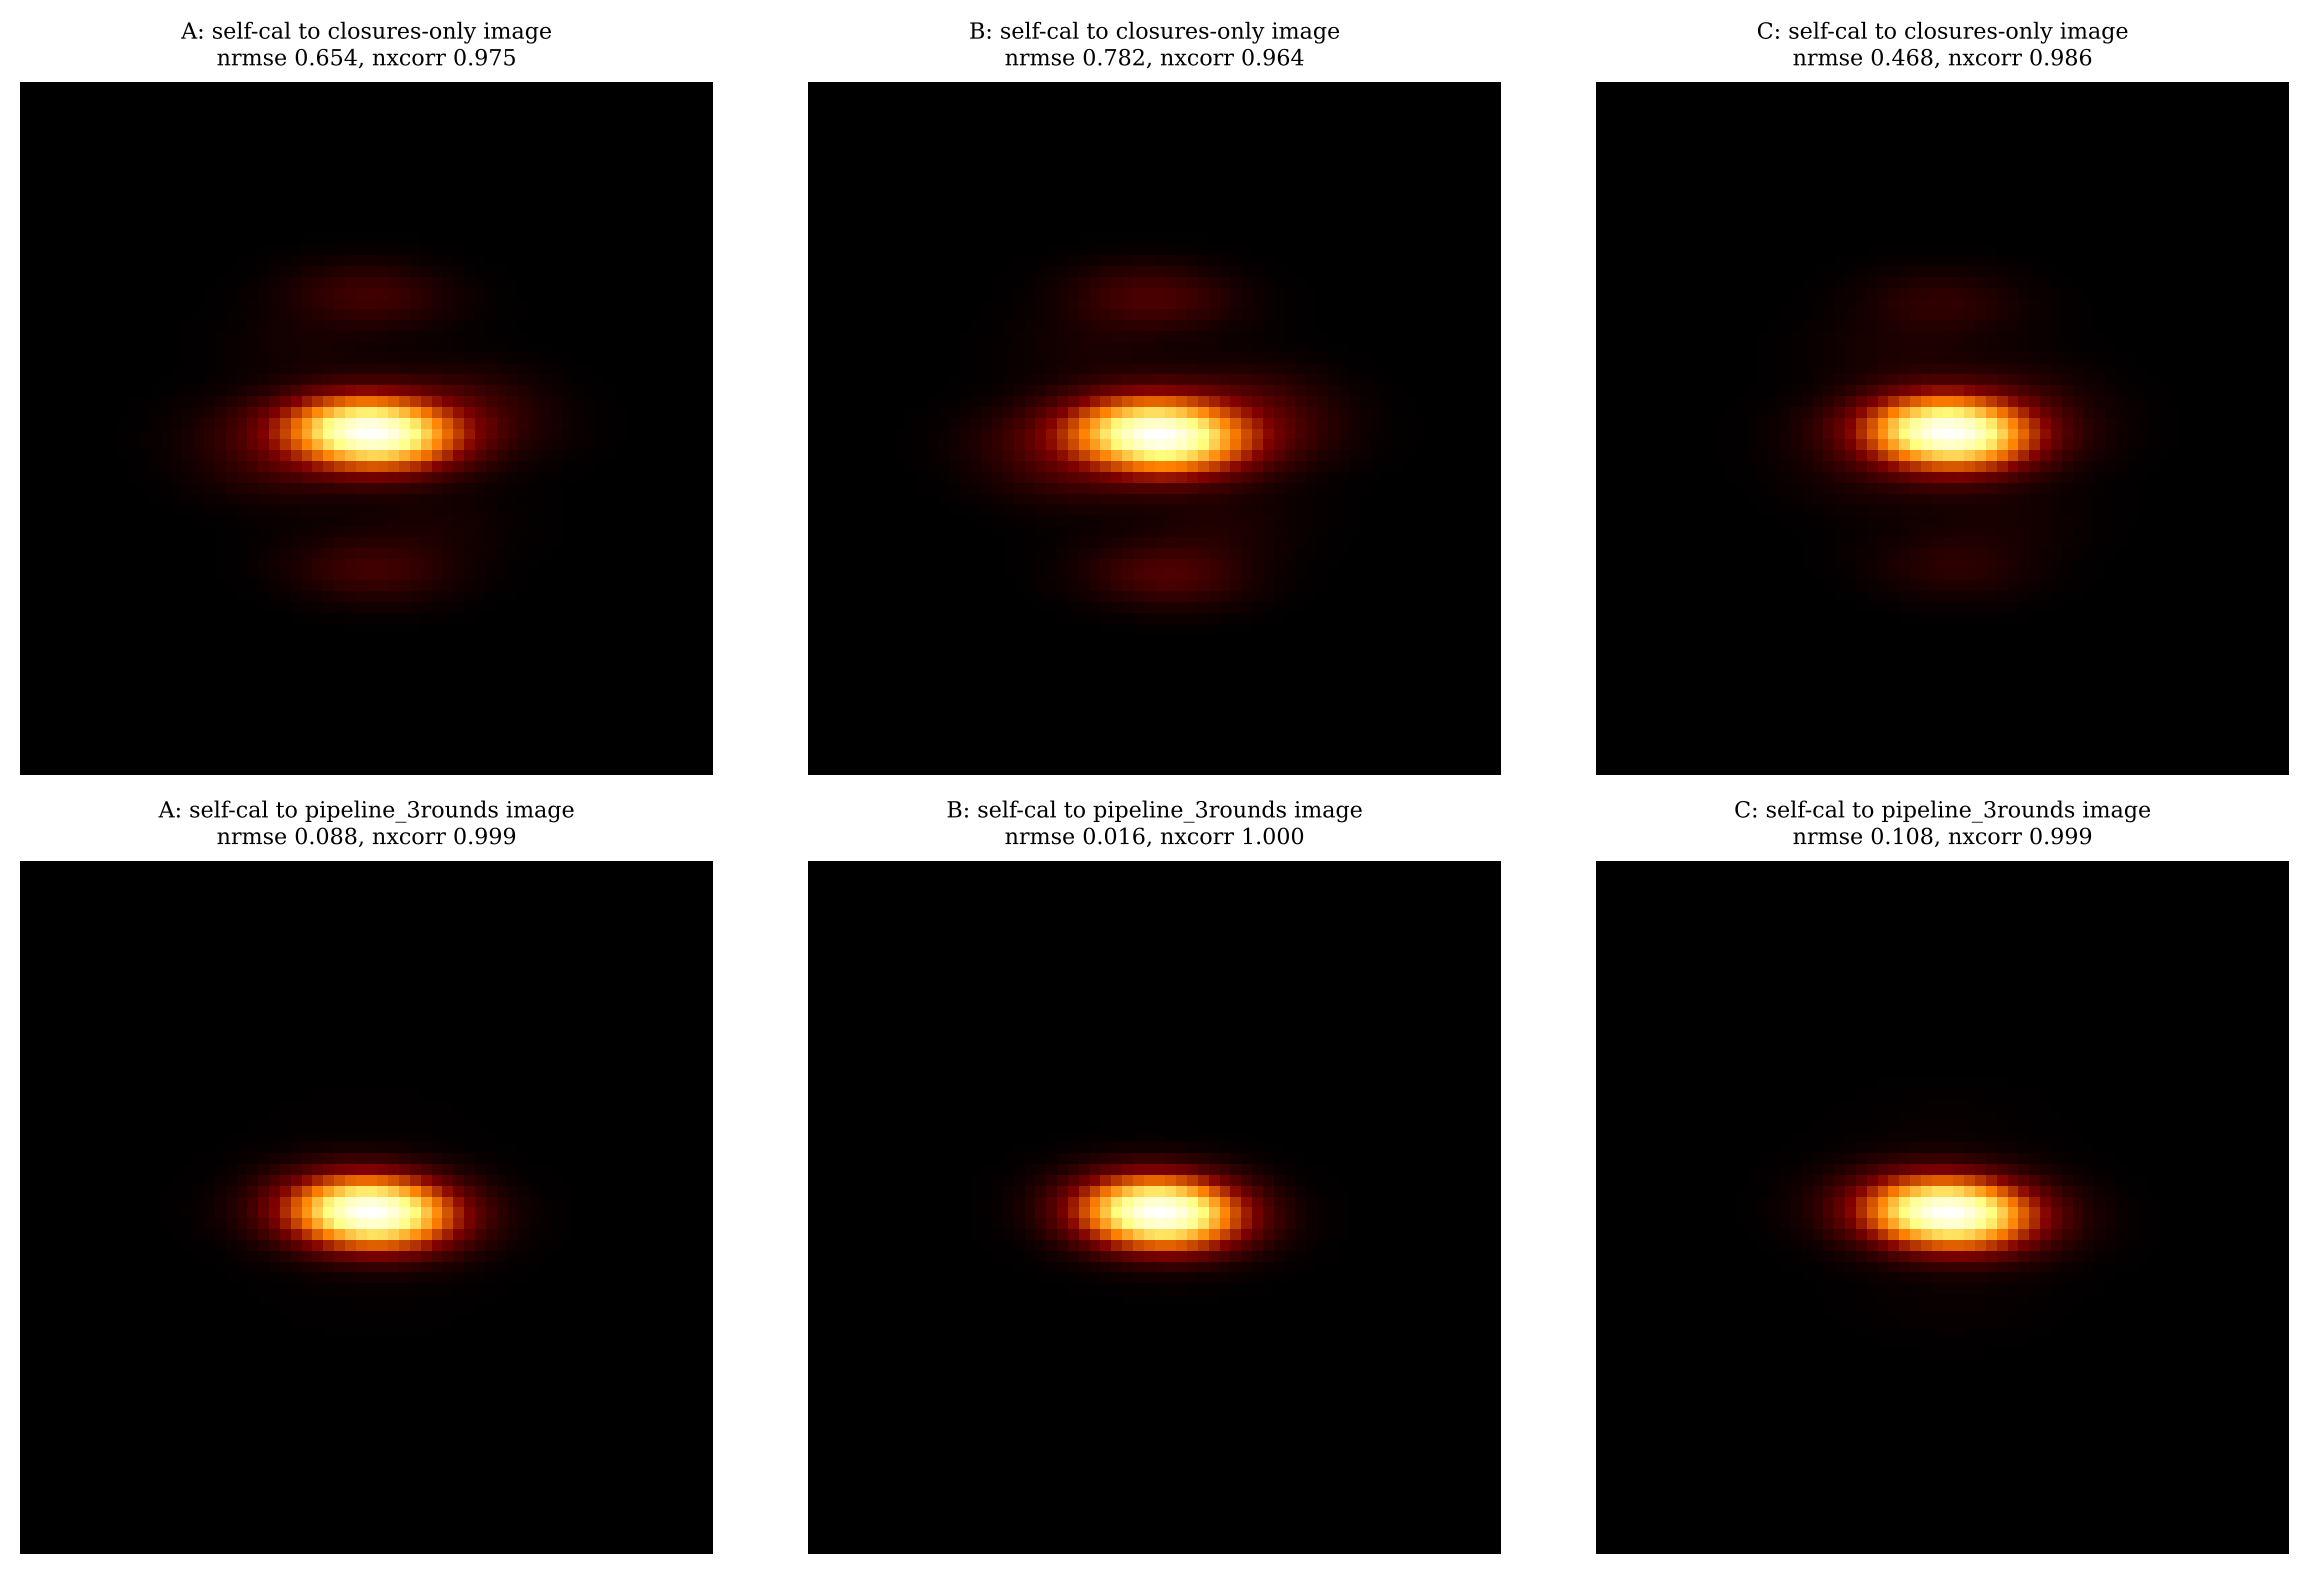

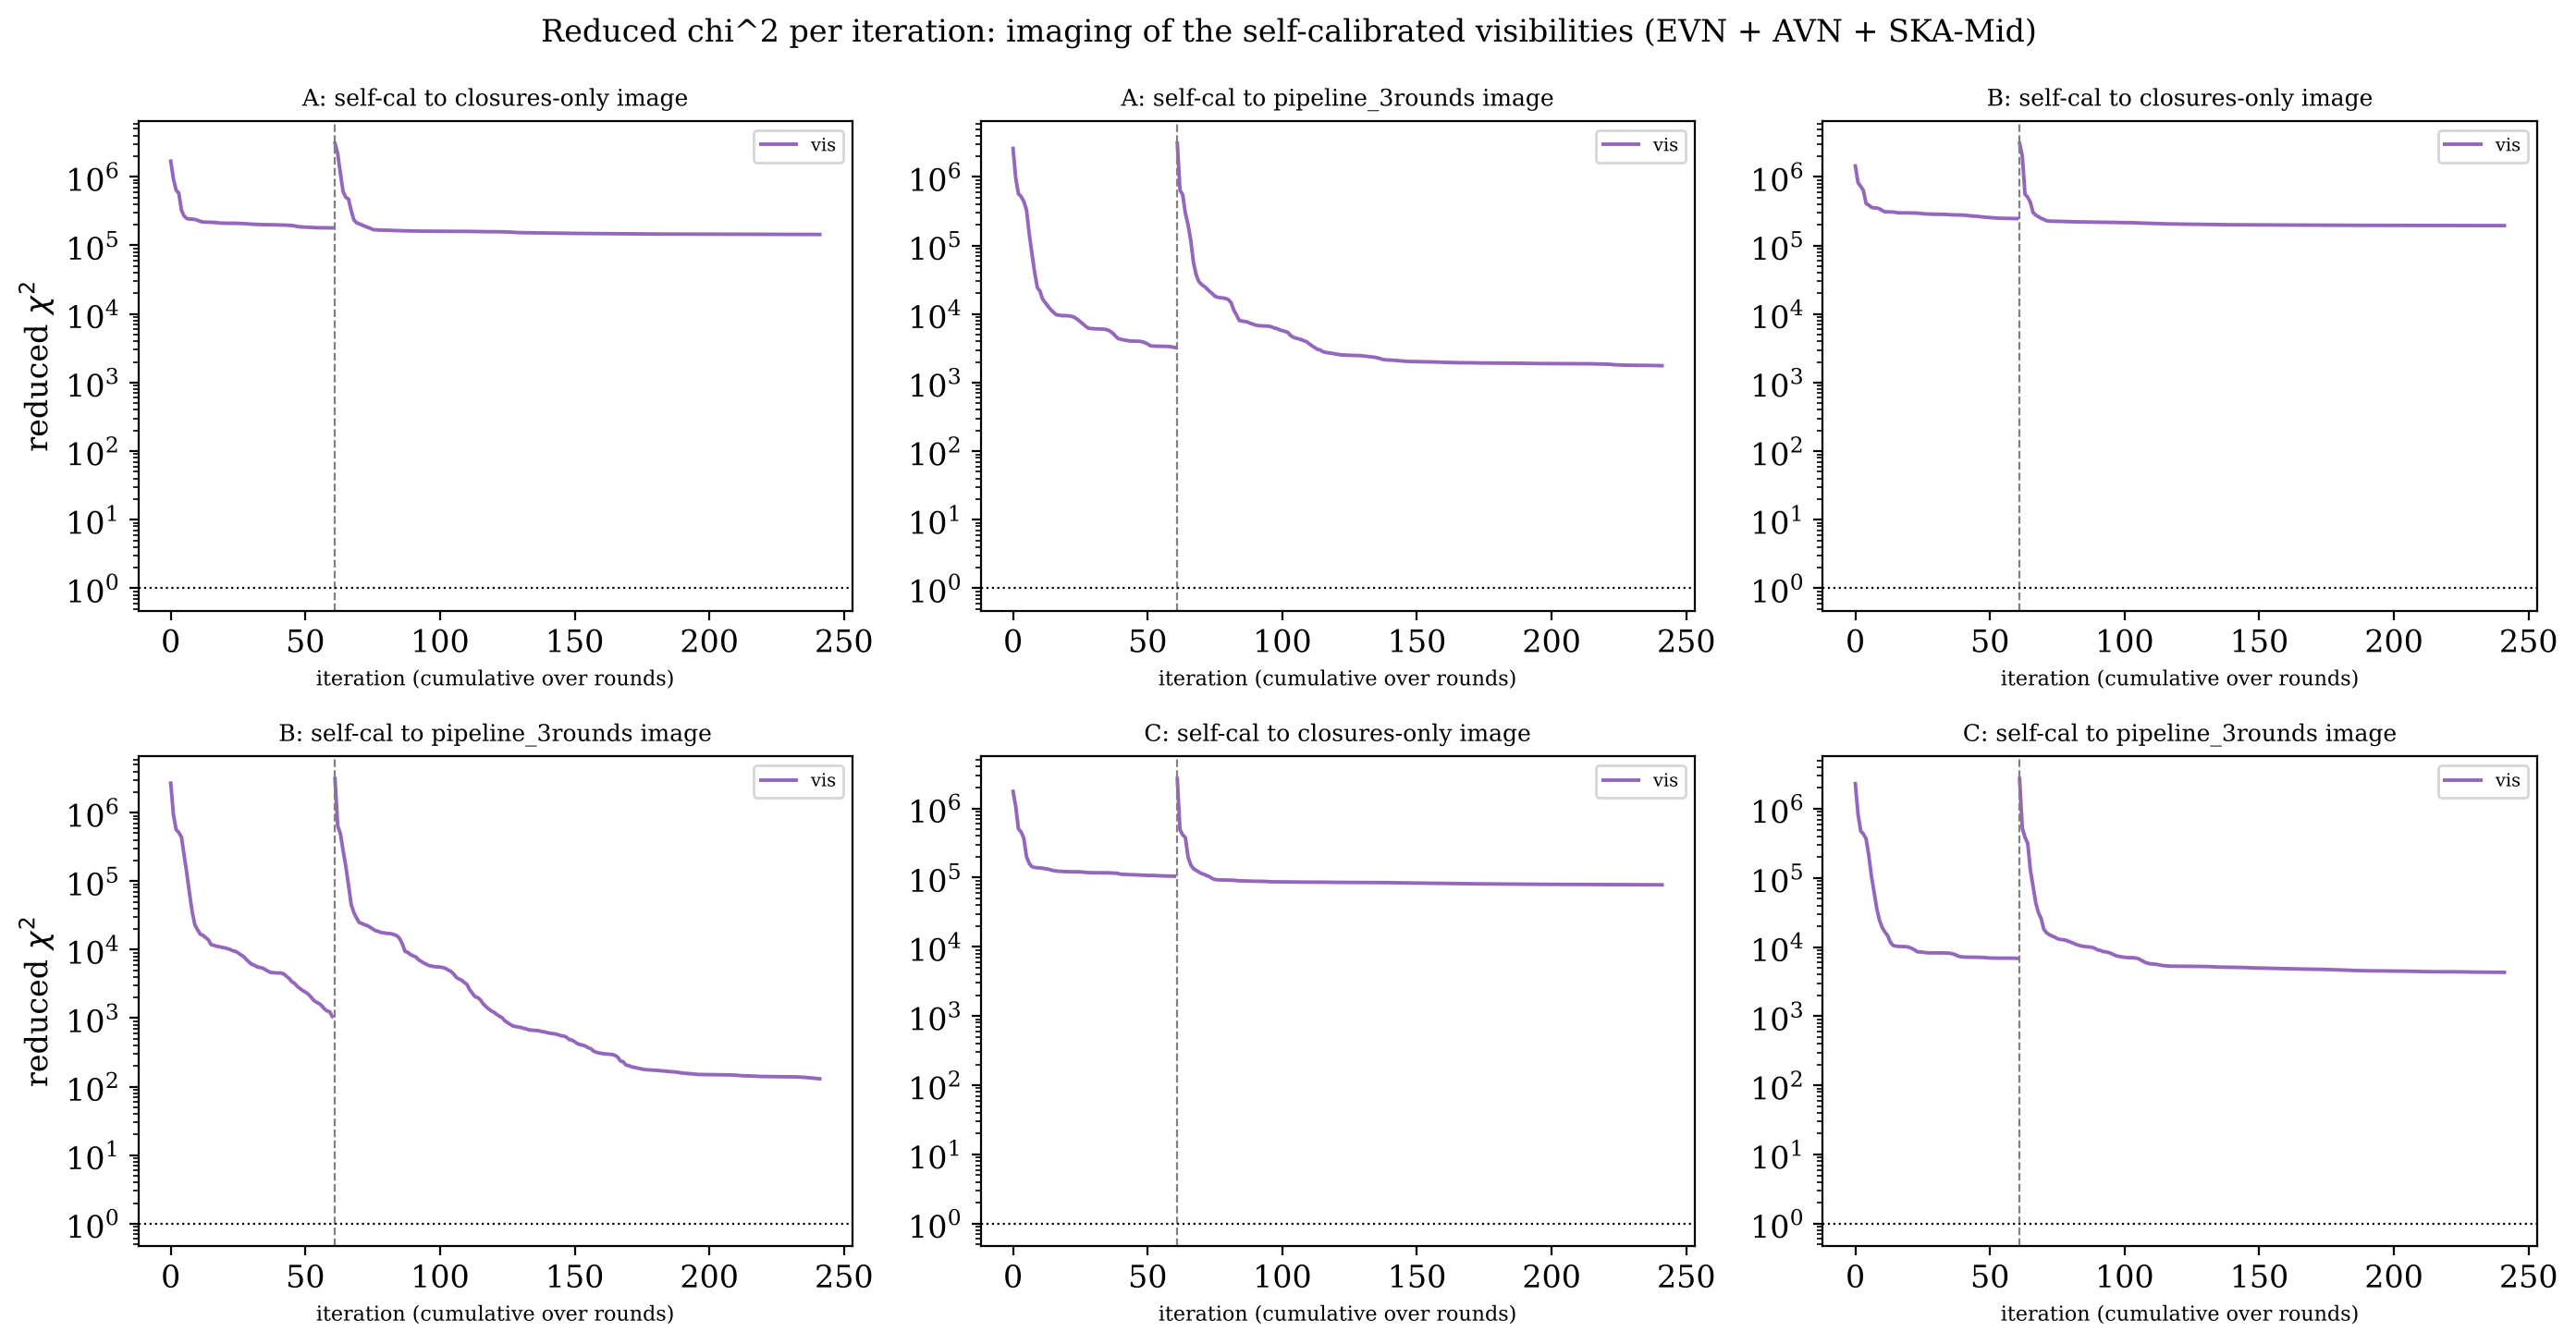

Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


(349 s)


In [18]:
from scipy import ndimage

def align_subpixel(im_model, im_truth):
    # Shift im_model (sub-pixel, Fourier shift) to the position that maximises its cross-correlation with im_truth.
    a = im_model.imvec.reshape(im_model.ydim, im_model.xdim); b = im_truth.imvec.reshape(im_truth.ydim, im_truth.xdim)
    cc = np.real(np.fft.ifft2(np.fft.fft2(b)*np.conj(np.fft.fft2(a))))
    ny, nx = cc.shape; iy, ix = np.unravel_index(np.argmax(cc), cc.shape)
    parab = lambda m, c, p: 0.5*(m - p)/(m - 2*c + p) if (m - 2*c + p) != 0 else 0.0
    dy = iy + parab(cc[(iy-1) % ny, ix], cc[iy, ix], cc[(iy+1) % ny, ix])
    dx = ix + parab(cc[iy, (ix-1) % nx], cc[iy, ix], cc[iy, (ix+1) % nx])
    dy = dy - ny if dy > ny/2 else dy; dx = dx - nx if dx > nx/2 else dx
    sh = np.clip(np.real(np.fft.ifft2(ndimage.fourier_shift(np.fft.fft2(a), (dy, dx)))), 0, None)
    out = im_model.copy(); out.imvec = (sh*im_model.total_flux()/sh.sum()).ravel()
    return out, np.hypot(dy, dx)*im_model.psize/mas

def vis_errors(o, ref, snr_min=5.0):
    # Calibrated (or raw) visibilities of `o` vs. the noise-free visibilities of `ref` (same schedule).
    key = lambda d: list(zip(np.round(d['time']*3600).astype(int), d['t1'], d['t2']))
    r = dict(zip(key(ref.data), ref.data['vis']))
    kk = key(o.data); m = np.array([k in r for k in kk])
    v, s = o.data['vis'][m], o.data['sigma'][m]
    vt = np.array([r[k] for k, mm in zip(kk, m) if mm])
    hi = np.abs(vt)/s > snr_min
    return (float(np.mean(np.abs(v - vt)**2/s**2)/2),
            float(np.median(np.abs(np.abs(v[hi])/np.abs(vt[hi]) - 1))*100),
            float(np.median(np.abs(np.degrees(np.angle(v[hi]*np.conj(vt[hi])))))))

truth_grid = im_src.regrid_image(fov, npix); truth_grid.imvec *= zbl/truth_grid.total_flux()
models = {'closures-only image': lambda s_: study[('Closures only (no self-cal)', s_)].unrestored,
          'pipeline_3rounds image': lambda s_: recs[f'{s_}  3-round pipeline'].unrestored}
raw_obs = {'A': obs_A, 'B': obs_B, 'C': obs_C}
oracle_obs = {'A': obs_A, 'B': cal_B_oracle, 'C': cal_C_oracle}

sc_cal, sc_recs, sc_hist, sc_rows = {}, {}, {}, []
t_sc = time.time()
for s_ in 'ABC':
    sc_rows.append((s_, 'raw data (no calibration)', np.nan) + vis_errors(raw_obs[s_], obs_ideal))
    for mname, get_model in models.items():
        model, shift = align_subpixel(get_model(s_), truth_grid)
        with contextlib.redirect_stdout(io.StringIO()):
            cal = sc.self_cal(raw_obs[s_], model, method='both', ttype='fast', scan_solutions=True, processes=1)
        sc_cal[(s_, mname)] = cal
        sc_rows.append((s_, f'self-cal to {mname}', shift) + vis_errors(cal, obs_ideal))
        lab = f'{s_}: self-cal to {mname}'
        sc_hist[lab] = []
        sc_recs[lab] = run_rml_imager(cal, prior, zbl, vis_rounds, history=sc_hist[lab]).blur_gauss(beam_params, frac=1.0)
    sc_rows.append((s_, 'oracle (true model)' if s_ != 'A' else 'oracle (A: data already calibrated)', np.nan)
                   + vis_errors(oracle_obs[s_], obs_ideal))
    print(f"  scenario {s_} done ({time.time()-t_sc:.0f} s)")

print(f"\n{'sc.':4s} {'visibilities':42s} {'model shift':>12s} {'chi2 vs truth':>14s} {'amp err [%]':>12s} {'phase err [deg]':>16s}")
for s_, name, shift, chi2_t, a_err, p_err in sc_rows:
    sh = '' if np.isnan(shift) else f'{shift:.3f} mas'
    print(f"{s_:4s} {name:42s} {sh:>12s} {chi2_t:14.2f} {a_err:12.2f} {p_err:16.2f}")

print(f"\nImages of the self-calibrated visibilities (vis_rounds, restored with the fitted dirty beam):")
print(f"{'reconstruction':42s} {'nrmse':>7s} {'nxcorr':>7s} {'flux [Jy]':>10s}")
sc_img_rows = []
for lab, im in sc_recs.items():
    xc, nr = fidelity(im)[:2]
    sc_img_rows.append((lab, nr, xc, im.total_flux()))
    print(f"{lab:42s} {nr:7.3f} {xc:7.3f} {im.total_flux():10.3f}")

# ---- Figure: visibility errors after self-calibration to each model, per scenario
groups = ['raw data (no calibration)', 'self-cal to closures-only image', 'self-cal to pipeline_3rounds image', 'oracle']
gcol = ['tab:gray', 'tab:blue', 'tab:orange', 'tab:green']
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for j, (col, ttl) in enumerate([(3, 'reduced $\\chi^2$ against the true visibilities'), (4, 'median amplitude error [%]'),
                                (5, 'median phase error [deg]')]):
    for g, (gname, c) in enumerate(zip(groups, gcol)):
        vals = [next(r[col] for r in sc_rows if r[0] == s_ and r[1].startswith(gname)) for s_ in 'ABC']
        ax[j].bar(np.arange(3) + (g - 1.5)*0.2, vals, 0.2, color=c, edgecolor='k', label=gname)
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels(['Scenario A', 'Scenario B', 'Scenario C'])
    ax[j].set_yscale('log'); ax[j].set_title(ttl, fontsize=10)
ax[0].axhline(1, color='k', ls=':', lw=1)
ax[2].legend(fontsize=8)
fig.suptitle('Raw data self-calibrated to the final images vs. the true visibilities (EVN + AVN + SKA-Mid)', fontsize=12)
plt.tight_layout(); save_fig(fig, '10_selfcal_to_final_images_visibility_errors'); plt.show()

# ---- Figure: images of the self-calibrated visibilities
h = fov/2/mas
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for r_, mname in enumerate(models):
    for c_, s_ in enumerate('ABC'):
        lab = f'{s_}: self-cal to {mname}'; im = sc_recs[lab]; nr_, xc_ = [(x[1], x[2]) for x in sc_img_rows if x[0] == lab][0]
        ax[r_, c_].imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot', extent=[h, -h, -h, h]); ax[r_, c_].axis('off')
        ax[r_, c_].set_title(f'{lab}\nnrmse {nr_:.3f}, nxcorr {xc_:.3f}', fontsize=8)
plt.tight_layout(); save_fig(fig, '10b_images_of_selfcalibrated_visibilities'); plt.show()

# ---- Figure: chi^2 at every iteration of the imaging of the self-calibrated visibilities
plot_chi2_histories(sc_hist, '10c_chi2_convergence_selfcalibrated_visibilities',
                    'Reduced chi^2 per iteration: imaging of the self-calibrated visibilities (EVN + AVN + SKA-Mid)', ncols=3)

# ---- Export: calibrated UVFITS and the tables of this section
for (s_, mname), cal in sc_cal.items():
    tag = 'closures_image' if mname.startswith('closures') else 'pipeline_image'
    try:
        cal.save_uvfits(f'{OUT_DIR}/visibilities/scenario{s_}_selfcal_to_{tag}.uvfits')
        cal.save_txt(f'{OUT_DIR}/visibilities/scenario{s_}_selfcal_to_{tag}.txt')
    except Exception as e:
        print('  [skipped]', s_, tag, e)
import csv
with open(f'{OUT_DIR}/tables/selfcal_to_final_images_visibility_errors.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['scenario', 'visibilities', 'model_shift_mas', 'chi2_vs_true_vis', 'median_amp_err_pct', 'median_phase_err_deg'])
    w.writerows(sc_rows)
with open(f'{OUT_DIR}/tables/selfcal_to_final_images_reconstructions.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['reconstruction', 'nrmse', 'nxcorr', 'total_flux_Jy']); w.writerows(sc_img_rows)
for lab, im in sc_recs.items():
    fn = lab.replace(': ', '_').replace(' ', '_').replace('-', '')
    try: im.save_fits(f'{OUT_DIR}/images/selfcalvis_{fn}.fits')
    except Exception as e: print('  [skipped]', lab, e)
print(f"({time.time()-t_sc:.0f} s)")

## 12. Discussion of the results

The numbers quoted here are those of the run saved in this notebook, made with the **EVN + AVN + SKA-Mid** array (20 stations, including the phased SKA-Mid core `S5` and three SKA-Mid dishes). Scenario A and the atmospheric screens of scenario C (ionospheric and tropospheric) are reproducible (fixed seeds). The station gains and phases of B and C, however, are drawn by `ehtim` from seeds derived from Python's string hash, which changes from one session to the next. Across runs the nrmse of A, B and C changes by up to a few hundredths, so only larger differences are discussed.

**Data quality and resolution.** The selected window (0–6 h UTC) gives 6314 visibilities on all 190 baselines, and all 1140 closure triangles have SNR > 5 on their three legs. The median SNR is ~830: a 1 Jy compact source is a very bright target for an array that contains the phased SKA-Mid (3.1 Jy SEFD). The **EVN alone (no SKA)** would give only 1742 visibilities in the same window. The longest projected baseline is 178 Mλ (10,600 km), a nominal resolution of 1.16 mas. The fitted beam is 2.18 × 0.87 mas (PA 88°), elongated east–west because the African stations (AVN and SKA-Mid) add mostly north–south baselines to the EVN. The 0.5 mas Gaussian is smaller than the beam and keeps 62% of its flux on the longest baselines: it is only partially resolved.

**Closure quantities behave as expected.** In A and B the closure-phase residuals with respect to the noise-free reference have an rms of 0.11°, exactly 1.00 and 1.01 times their thermal sigma: the gain and phase errors of B cancel in every triangle. In C the rms is 0.27°, **6.1 sigma**. The in-band and in-scan averaging of the atmospheric corruptions (mean |Γ| = 0.92, minimum 0.52) is not antenna-based, so it leaves a closure error that is small in degrees but large compared with the thermal noise. The oracle self-calibration shows the same: with the true model, B reaches a reduced χ² of 0.91 and C stays at ~3200.

**At 5 GHz the decorrelation of scenario C comes from the tropospheric delay, not from the ionosphere.** With the dTEC term alone the mean |Γ| is 0.9995; with the delay term alone, 0.92. An idealised fringe fit raises it to 0.989. The same atmospheric corruptions at 250 MHz (LBA + SKA-Low notebook) are dominated by their ionospheric part.

**Reconstructions (Sections 8–9).**

| `pipeline_3rounds` | nrmse | flux [Jy] | compact flux / true | dynamic range |
|---|---|---|---|---|
| A | 0.02 | 0.99 | 0.98 | ~1570 |
| B | 0.01 | 1.00 | 0.99 | ~1930 |
| C | 0.09 | 1.01 | 0.96 | ~730 |
| C after idealised fringe fit | 0.02 | 1.00 | 0.99 | ~1730 |
| C, oracle pipeline | 0.01 | 1.00 | 0.99 | ~2070 |
| B / C raw visibilities | 8.9 / 10.1 | 0.15 / 0.14 | 0.08 / 0.08 | 33 / 29 |

* **A and B are equivalent:** the pipeline removes the 15% gain offsets and the random phases of B without knowing the source.
* **C keeps shape and flux but loses dynamic range** (a factor ~2.5), and the residual map shows a structured pattern on the source.
* **A fringe fit would recover C almost completely** (nrmse 0.02, dynamic range ~1700, like B).
* **Raw visibilities fail completely**: the image keeps ~15% of the flux, displaced and fragmented.

**Convergence (χ² per iteration, figures 07, 07b, 09b).** In A and B the closure phases reach χ² ≈ 1.1–1.3 in round 1, while the log closure amplitudes stop at 20–33. In rounds 2–3 the bispectrum and amplitude χ² fall steadily to 20–60 without flattening. At a median SNR of ~830, a 0.1% amplitude mismatch is already 1σ, and the pixel grid and the FFT used in imaging set a floor well above 1, which does not affect the image fidelity. In C every term flattens from the first iterations of each round, at ~2000 (bs) and ~6000 (amp, logcamp): no image, together with antenna-based gains, can reproduce decorrelated amplitudes and non-closing phases. The oracle pipeline on C flattens at the same values. The raw-visibility runs stay at χ² ≈ 10⁷.

**Imaging strategies (Section 10).** nrmse of closures only / `pipeline_3rounds` / oracle: 0.12 / 0.02 / 0.01 (A), 0.13 / 0.01 / 0.02 (B), 0.14 / 0.09 / 0.01 (C). For this source smaller than the beam, the self-calibration steps of the pipeline improve strongly on the closures-only images. The χ² histories show why: the closure-only runs end with logcamp χ² ≈ 5–8 (A, B) and ~6000 (C), i.e. the closure amplitudes alone do not pin down the size and flux distribution of a sub-beam source at this SNR.

**Self-calibration to the final images (Section 11): how well do the closures work?**

| Scen. | Visibilities | χ² vs. true | Amp. error | Phase error |
|---|---|---|---|---|
| A | raw (= oracle) | 1.0 | 0.07 % | 0.04° |
| A | self-cal to closures-only image | 8×10⁶ | 38 % | 2.4° |
| A | self-cal to pipeline image | 6×10⁴ | 4.6 % | 1.0° |
| B | raw | 1×10⁷ | 8.8 % | 91° |
| B | self-cal to closures-only image | 2×10⁷ | 59 % | 3.5° |
| B | self-cal to pipeline image | 2100 | 1.0 % | 0.28° |
| B | oracle | 0.91 | 0.07 % | 0.04° |
| C | raw | 1×10⁷ | 9.5 % | 91° |
| C | self-cal to closures-only image | 3×10⁶ | 28 % | 3.3° |
| C | self-cal to pipeline image | 6×10⁴ | 6.1 % | 0.23° |
| C | oracle | 3200 | 2.8 % | 0.09° |

* **The closures fix the phases.** Self-calibration to the closures-only image brings the phase errors from 91° to 2–3.5°. The closure phases alone tell where the emission is, to a small fraction of the beam.
* **The closures do not fix the amplitudes of a sub-beam source.** The unrestored closures-only image has the wrong radial profile, and an amplitude-and-phase self-calibration forces it onto the data: amplitude errors of 28–59%, worse than the uncalibrated data (9%). The images made from these visibilities (figure 10b) are too broad and have north–south sidelobes (nrmse 0.47–0.78). This is the classic reason why the first self-calibration of hybrid mapping should be **phase only** (as in the 5 GHz jet notebook).
* **The pipeline image is a good model**, with 1% amplitude and 0.3° phase errors in B. Re-imaging those data gives nrmse 0.016, as good as the oracle. In C the pipeline image calibrates the phases to 0.23°, better than the closures alone, and the remaining amplitude error (6%) is close to the oracle's own floor (2.8%) set by the decorrelation.
* **The χ² against the true visibilities is extremely sensitive at this SNR.** Even 1% amplitude errors give χ² ≈ 2000. The fractional errors are therefore the more useful measure here, and the χ² ranks the calibrations consistently.

In short: with the EVN + AVN + SKA-Mid at 5 GHz, antenna-based errors (A, B) are fully removed by closures plus iterative self-calibration. For a source smaller than the beam the closure quantities alone recover the phases but not the amplitudes, so a closure image should first be used for a phase-only self-calibration. In C the limit is the decorrelation driven by the tropospheric delay, which a fringe fit removes.

## 13. Export everything to a single folder

Collects in one folder (`results_VLBI_5GHz_Gaussian/`) and in one zip file (`results_VLBI_5GHz_Gaussian.zip`):
* `visibilities/`: the visibilities of the reference observation and of scenarios A, B, C (plus scenario C after the idealised fringe fit, and the oracle self-calibrated B and C), each in `.uvfits` (for AIPS, CASA, Difmap) and `.txt`;
* `figures/`: every figure of the notebook as `.png`;
* `images/`: the input model, the restored input model and all reconstructions as `.fits`;
* `tables/`: metrics tables, the final $\chi^2$ per round, a table of the regularizers and weights of every pipeline (`pipelines_regularizers.csv/.md`, with the chosen one marked), SEFD values and the atmospheric corruptions of scenario C (ionospheric dTEC and tropospheric delay screens), plus the array files and a `README.txt`.

In Google Colab the zip file is downloaded automatically; otherwise it is left next to the notebook.

In [19]:
import shutil, csv, datetime

def _try(label, fn):
    try: fn()
    except Exception as e: print(f"  [skipped] {label}: {e}")

# ---- 1. Visibilities
obs_set = {'reference_noerrors': obs_ideal, 'scenarioA': obs_A, 'scenarioB': obs_B, 'scenarioC': obs_C,
           'scenarioC_after_idealised_fringefit': obs_Cff, 'scenarioB_selfcal_oracle': cal_B_oracle, 'scenarioC_selfcal_oracle': cal_C_oracle}
for name, o in obs_set.items():
    with silent():
        _try(f'{name}.uvfits', lambda: o.save_uvfits(f'{OUT_DIR}/visibilities/{name}.uvfits'))
        _try(f'{name}.txt',    lambda: o.save_txt(f'{OUT_DIR}/visibilities/{name}.txt'))

# ---- 2. Images (FITS)
_try('input model', lambda: im_src.save_fits(f'{OUT_DIR}/images/input_model.fits'))
_try('restored truth', lambda: truth_g.save_fits(f'{OUT_DIR}/images/input_model_restored.fits'))
for k, im in recs.items():
    fn = k.replace('  ', '_').replace(' ', '_').replace('-', '')
    _try(k, lambda: im.save_fits(f'{OUT_DIR}/images/rec_{fn}.fits'))
for (name, sc_name), im in study.items():
    fn = name.replace(' ', '_').replace('(', '').replace(')', '').replace('-', '')
    _try(name, lambda: im.save_fits(f'{OUT_DIR}/images/study_{fn}_{sc_name}.fits'))

# ---- 3. Tables
with open(f'{OUT_DIR}/tables/metrics_reconstructions.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['reconstruction', 'compact_flux_over_true', 'peak_offset_mas', 'dynamic_range', 'total_flux_Jy', 'nrmse', 'nxcorr'])
    w.writerows([[r[0]] + [f'{x:.4f}' for x in r[1:]] for r in metrics_rows])
with open(f'{OUT_DIR}/tables/metrics_imaging_strategies.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['pipeline', 'scenario', 'nrmse', 'nxcorr', 'total_flux_Jy'])
    w.writerows([[r[0], r[1]] + [f'{x:.4f}' for x in r[2:]] for r in study_rows])
with open(f'{OUT_DIR}/tables/chi2_final_per_round.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['scenario', 'round'] + terms); w.writerows(chi2_rows)
with open(f'{OUT_DIR}/tables/sefd_5GHz.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['station', 'network', 'name', 'SEFD_used_Jy'])
    for k, v in sefd.items(): w.writerow([k, network(k), names[k], f'{v:.2f}'])
np.savez(f'{OUT_DIR}/tables/screen_scenarioC.npz', sites=scr['sites'], t_h=scr['t'], dtec_TECU=scr['dtec'], tau_ns=scr['tau_ns'])
shutil.copy('data/evn_avn_array.txt', f'{OUT_DIR}/tables/array_EVN_AVN_SKAMid.txt')
shutil.copy('data/evn_array.txt', f'{OUT_DIR}/tables/array_EVN_alone_noSKA.txt')

# ---- 3b. Regularizers and weights of every pipeline
pipelines = {
 'pipeline_3rounds':            (pipeline_3rounds,        "CHOSEN. Used for scenarios A, B and C (Sections 8-9). Self-calibrates to its own previous image, never to the truth; closure-only first round, then bispectrum + amplitudes, total variation in the last round to refine the edges. Same prior, rounds and weights for the three scenarios so they are comparable."),
 'pipeline_oracle':             (pipeline_oracle,         "Reference (best case). Same structure but self-calibrates to the true model; not realistic, only shows the cost of not knowing the source."),
 'closures_only (Section 10)':  (candidates['Closures only (no self-cal)'], "Baseline. Closure quantities only, no calibration at all."),
 'closure_rounds_handson':      (closure_rounds_handson,  "Reference. Closure strategy of the ehtim hands-on, on oracle-calibrated data (row 'C hands-on rounds')."),
 'vis_rounds':                  (vis_rounds,              "Reference. Fits raw visibilities directly (rows 'B/C raw visibilities'); no calibration, expected to fail with gain/phase errors."),
}
reg_names = {'simple': 'Entropy', 'tv': 'Total variation', 'flux': 'Total flux', 'cm': 'Centre of mass'}
pipe_rows = []
for pname, (rounds, why) in pipelines.items():
    for r, rnd in enumerate(rounds, 1):
        sc_ = rnd.get('selfcal'); sc_txt = {'both': 'amp+phase to own image', 'phase': 'phase only to own image', 'oracle': 'amp+phase to TRUE model'}.get(sc_, 'none') if sc_ else ('calibrated data (oracle)' if rnd.get('switch_obs') else 'none')
        pipe_rows.append([pname, r,
            '; '.join(f'{k}={v}' for k, v in rnd['data_term'].items()),
            '; '.join(f'{reg_names.get(k, k)} ({k})={v}' for k, v in rnd['reg_term'].items()),
            rnd['maxit'], rnd.get('blur_frac', 0.0), sc_txt, 'CHOSEN' if pname == 'pipeline_3rounds' else '', why if r == 1 else ''])
hdr = ['pipeline', 'round', 'data terms (weight)', 'regularizers (weight)', 'maxit', 'blur_frac', 'self-cal before round', 'status', 'role / why']
with open(f'{OUT_DIR}/tables/pipelines_regularizers.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(hdr); w.writerows(pipe_rows)
with open(f'{OUT_DIR}/tables/pipelines_regularizers.md', 'w') as f:
    f.write('| ' + ' | '.join(hdr) + ' |\n|' + '---|'*len(hdr) + '\n')
    for r in pipe_rows: f.write('| ' + ' | '.join(str(x) for x in r) + ' |\n')
    f.write(f"\nShared settings: prior = Gaussian of FWHM {prior_fwhm/mas:.2f} mas; grid {npix}x{npix} over {fov/mas:.1f} mas; "
            f"regularizer weights w_simple={w_simple}, w_tv={w_tv}; flux/cm weights {FM} (closure-only rounds: {FM_CL}); self-cal before round 2: {selfcal_round2}; final restoring beam = fitted dirty beam ({beam_weighting} weighting).\n")
    f.write("\nWhy pipeline_3rounds is the chosen one: it is the only realistic pipeline that needs no knowledge of the truth and no pre-calibrated data, "
            "it is the one reported for A, B and C, and Section 10 compares it with the closures-only baseline and the oracle.\n")
try:
    import pandas as pd
    from IPython.display import display
    display(pd.DataFrame(pipe_rows, columns=hdr).drop(columns='role / why'))
except ImportError:
    pass
print("Chosen pipeline: pipeline_3rounds (see tables/pipelines_regularizers.md for the full explanation)")

# ---- 4. README + zip
with open(f'{OUT_DIR}/README.txt', 'w') as f:
    f.write(f"""RADIOBLOCKS A/B/C at {nu/1e9:.0f} GHz, EVN + AVN + SKA-Mid ({len(array_comb.tarr)} stations, SKA-Mid included)
Generated: {datetime.datetime.now():%Y-%m-%d %H:%M}
Source: Gaussian source, {flux_jy:.2f} Jy, RA {src_ra_h:.3f} h, Dec {src_dec_deg:.2f} deg
Window: {tstart}-{tstop} h UTC | tint={tint}s tadv={tadv}s avg_time={avg_time}s | elevmin={elevation_min} deg | bw={bw/1e6:.0f} MHz
Restoring beam: {beam_params[0]/mas:.2f} x {beam_params[1]/mas:.2f} mas, PA {np.degrees(beam_params[2]):.0f} deg ({beam_weighting})
SEFD used [Jy]: """ + ', '.join(f'{k}={v:.1f}' for k, v in sefd.items()) + """
visibilities/ : .uvfits and .txt   figures/ : .png   images/ : .fits   tables/ : csv, md, npz, array files (pipelines_regularizers.* lists regularizers/weights per pipeline and the chosen one)
""")
zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
print(f"Everything saved in '{OUT_DIR}/' and zipped as '{zip_path}'")
for sub in ('visibilities', 'figures', 'images', 'tables'):
    print(f"  {sub:13s}: {len(os.listdir(f'{OUT_DIR}/{sub}'))} files")

try:                                   # automatic download in Google Colab
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

,pipeline,round,data terms (weight),regularizers (weight),maxit,blur_frac,self-cal before round,status
0,pipeline_3rounds,1,cphase=100; logcamp=50,Entropy (simple)=100; Total flux (flux)=100000...,100,0.0,none,CHOSEN
1,pipeline_3rounds,2,bs=100; amp=50,Entropy (simple)=100; Total flux (flux)=100000...,150,1.0,amp+phase to own image,CHOSEN
2,pipeline_3rounds,3,bs=100; amp=50,Total variation (tv)=10; Total flux (flux)=100...,150,0.5,amp+phase to own image,CHOSEN
3,pipeline_oracle,1,bs=100,Entropy (simple)=100; Total flux (flux)=100000...,100,0.0,none,
4,pipeline_oracle,2,bs=100; amp=50,Entropy (simple)=100; Total flux (flux)=100000...,150,1.0,amp+phase to TRUE model,
5,pipeline_oracle,3,bs=100; amp=50,Total variation (tv)=10; Total flux (flux)=100...,150,0.5,none,
6,closures_only (Section 10),1,cphase=100; logcamp=50,Entropy (simple)=100; Total flux (flux)=100000...,100,0.0,none,
7,closures_only (Section 10),2,cphase=100; logcamp=50,Total variation (tv)=10; Total flux (flux)=100...,150,1.0,none,
8,closures_only (Section 10),3,cphase=100; logcamp=50,Total variation (tv)=10; Total flux (flux)=100...,150,0.5,none,
9,closure_rounds_handson,1,bs=100,Entropy (simple)=10; Total flux (flux)=100000....,60,0.0,none,


Chosen pipeline: pipeline_3rounds (see tables/pipelines_regularizers.md for the full explanation)


Everything saved in 'results_VLBI_5GHz_Gaussian/' and zipped as '/home/claude/work/v2_gauss/results_VLBI_5GHz_Gaussian.zip'
  visibilities : 26 files
  figures      : 14 files
  images       : 25 files
  tables       : 11 files


## 14. Conclusions and limitations

* **What the experiment measures.** With a fixed pipeline (same prior, rounds and regularization for A, B and C), the fidelity of the reconstruction of a compact 1 Jy source at 5 GHz with the **EVN + AVN + SKA-Mid** as a function of the corruption. Scenarios A and B are recovered to the same level (nrmse ≤ 0.02, dynamic range ~1600–1900): closure quantities plus self-calibration remove antenna-based gain and phase errors completely. Scenario C keeps the right shape and flux but loses about a factor 2.5 in dynamic range, because the in-band and in-scan decorrelation is not antenna-based.
* **How well do the closures work? (Section 11).** For this source, smaller than the beam, the closure quantities alone recover the **phases** (self-calibration to the closures-only image leaves 2–3.5° phase errors, from 91°) but not the **amplitudes**: amplitude self-calibration to the closures-only image introduces 28–59% errors. The final pipeline image is a good self-calibration model (1% and 0.3° in B). In practice, a closure-only image should be used first for a phase-only self-calibration.
* **Frequency dependence of scenario C.** With the same atmospheric corruptions as the 250 MHz LBA + SKA-Low notebook, their ionospheric part is negligible at 5 GHz (mean |Γ| = 0.9995) and the decorrelation comes from their tropospheric (delay) part (0.92). An idealised fringe fit removes most of it (0.989) and restores a B-level image. The natural extension is to sweep `tau0_sigma_ns`, `tau_rate_ns` and `dtec_rate` (Section 6) with the imaging fixed, and to add a real fringe-fit step to the pipeline.
* **Source model.** A single centred circular Gaussian smaller than the beam is easy to interpret (closure phases of zero, known flux and position) and a forgiving test for the restored image, but, as Section 11 shows, a demanding one for closure amplitudes. The jet notebook stresses the closure-based reconstruction with real structure.
* **Sensitivities.** The EVN SEFDs are typical published C-band values; the **SKA-Mid** and AVN SEFDs are assumptions for a future network, and the phased SKA-Mid core (3.1 Jy) dominates the sensitivity. At a median SNR of ~830, errors of a fraction of a per cent are already significant, which is why the reduced χ² never reaches 1 even in scenario A.
* **Self-calibration.** The pipeline self-calibrates to its own images (never to the truth); the oracle results are only a best-case reference. The total flux is held at the true value by a strong `flux` regularizer, i.e. it is assumed to be known from short baselines or a single-dish measurement.
* **Simulation and imaging transforms.** The data are simulated with the exact DFT and imaged with the FFT on a different pixel grid, which sets a small floor to the achievable χ².
* **Reproducibility.** The gains and phases of B and C depend on the Python hash seed; their metrics vary by a few hundredths between runs (use `PYTHONHASHSEED` to fix them).
* **Observing window and elevation limits.** The 6-h window is chosen automatically for this source; a single minimum elevation is applied to all stations.
* **Not modelled.** A fringe-fit step in the pipeline (only its idealised effect is shown), polarization leakage and Faraday rotation, interstellar scattering, the source spectrum within the band, and elevation-dependent system temperatures.

## References

* Chael, A. A., et al. 2018, *Interferometric imaging directly with closure phases and closure amplitudes*, ApJ 857, 23 (`ehtim`, https://github.com/achael/eht-imaging).
* Chael, A. A., et al. 2016, *High-resolution linear polarimetric imaging for the Event Horizon Telescope*, ApJ 829, 11 (RML imaging with `ehtim`).
* EVN status table (SEFDs of the EVN stations per band): https://evlbi.org/sites/default/files/shared/EVNstatus.txt
* Li, Y., Xu, Y., Li, J., et al. 2024, *VLBI with SKA: Possible Arrays and Astrometric Science*, Research in Astronomy and Astrophysics, arXiv:2404.14663. Table A1: positions, apertures and SEFDs of EVN, AVN and other antennas.
* Gaylard, M. J., et al. 2011, *An African VLBI Network of radio telescopes*, Proc. SAIP 2011, arXiv:1405.7214.
* RADIOBLOCKS project: scenario definitions A, B, C shared with the LBA + SKA-Low 250 MHz notebook of this delivery.